# Electricity consumption forecasting project

Goal: Forecast (predict) household electricity consumption several hours into the future.

Dataset used: Hebrail, G. & Berard, A. (2006). Individual Household Electric Power Consumption [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C58K54.

# Setup

In [1]:
# Downloads
!pip install ucimlrepo

In [127]:
# Imports
from ucimlrepo import fetch_ucirepo
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import math

import scipy
from scipy.stats import loguniform, randint

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

import torch
from torch.utils.data import DataLoader, TensorDataset

import joblib

In [3]:
# Our random state:
rs = 42

# Download data

In [4]:
# Note: Copied from UCI

# fetch dataset
individual_household_electric_power_consumption = fetch_ucirepo(id=235)

/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


In [5]:
# data (as pandas dataframes)
df_raw = individual_household_electric_power_consumption.data.features
df = df_raw.copy()

# metadata
print(individual_household_electric_power_consumption.metadata)

# variable information
print(individual_household_electric_power_consumption.variables)

{'uci_id': 235, 'name': 'Individual Household Electric Power Consumption', 'repository_url': 'https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption', 'data_url': 'https://archive.ics.uci.edu/static/public/235/data.csv', 'abstract': 'Measurements of electric power consumption in one household with a one-minute sampling rate over a period of almost 4 years. Different electrical quantities and some sub-metering values are available.', 'area': 'Physics and Chemistry', 'tasks': ['Regression', 'Clustering'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 2075259, 'num_features': 9, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2006, 'last_updated': 'Fri Mar 08 2024', 'dataset_doi': '10.24432/C58K54', 'creators': ['Georges Hebrail', 'Alice Berard'], 'intro_paper': None, 'additional_info': {'summary': 'This archiv

## Quick look at the data structure

In [6]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    object 
 3   Global_reactive_power  object 
 4   Voltage                object 
 5   Global_intensity       object 
 6   Sub_metering_1         object 
 7   Sub_metering_2         object 
 8   Sub_metering_3         float64
dtypes: float64(1), object(8)
memory usage: 142.5+ MB


In [8]:
df["Global_active_power"].value_counts()[:3]

,count
Global_active_power,
?,25979
0.218,9491
0.216,9319


In [9]:
df["Voltage"].value_counts()[:3]

,count
Voltage,
?,25979
241.180,3519
241.020,3251


This shows that the missing values are assigned the value "?". This explains why most features are of type object rather than float64. These missing value needs to be taken care of later. The question mark problem also makes the describe function useless. We'll need to take care of the question marks before also being able to plot.

In [10]:
df = df.replace("?", np.nan)
df.isna().sum()

,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979


In [11]:
# Some feature's that are numeric are described as object, so we'll fix that

numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df[numeric_cols] = df[numeric_cols].astype(float) # or the safer .apply(pd.to_numeric, errors="coerce")

In [12]:
df["datetime"] = pd.to_datetime( df["Date"] + " " + df["Time"])

df = df.set_index("datetime")
df = df.drop(columns=["Date", "Time"])

/tmp/ipykernel_2314/2545001271.py:1: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["datetime"] = pd.to_datetime( df["Date"] + " " + df["Time"])


In [13]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB


In [15]:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
mean,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


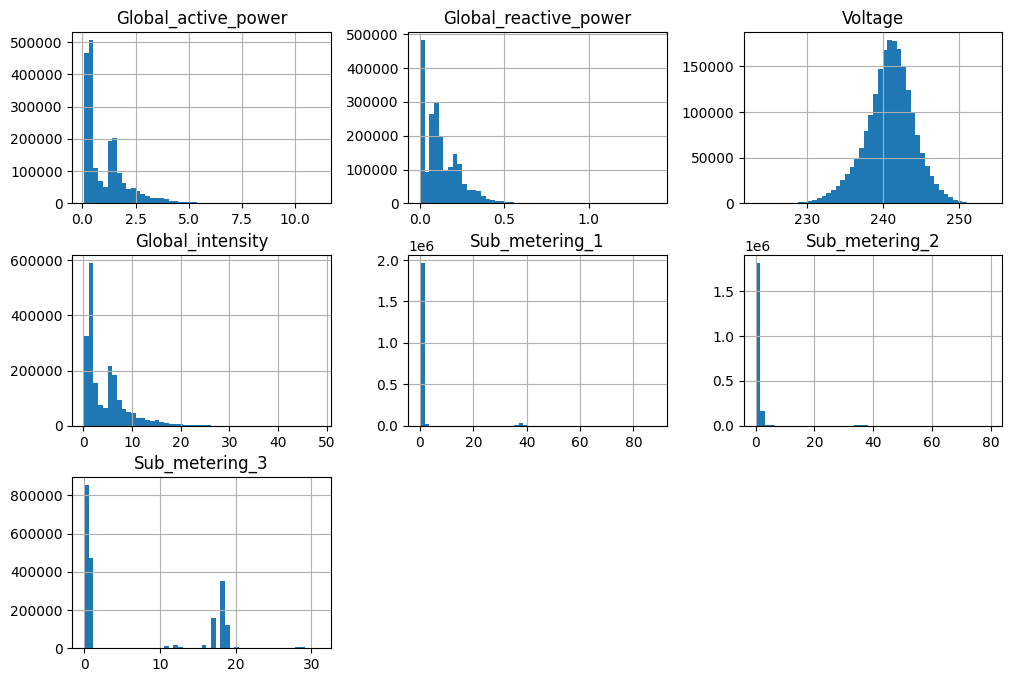

In [16]:
df.hist(bins=50, figsize=(12,8))
plt.show()

Note: Global_intensity is the value we want to predict

Now that we've looked at the data and fixed it's issues, we can start working with it.

# Aggregate data

We'll do hourly predictions, since minutely is too detailed for us, and thus we can aggregate our data.

In [17]:
df = df.resample("1h").mean()
df.head(3)

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333


A quick look at the aggregated data:

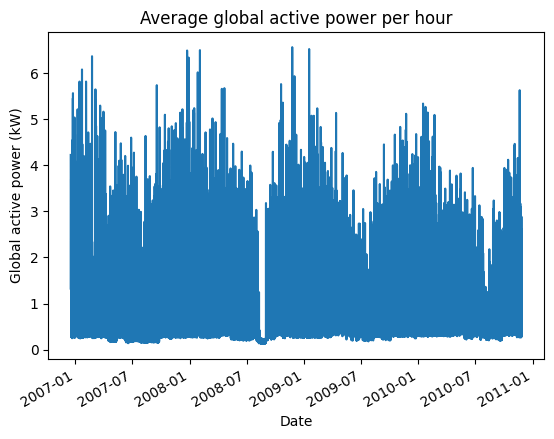

In [18]:
fig, ax = plt.subplots(1,1)
ax.plot(df.index, df["Global_active_power"])
ax.set_title("Average global active power per hour")
ax.set_xlabel("Date")
ax.set_ylabel("Global active power (kW)")
fig.autofmt_xdate()
plt.show()

Something interesting happened between 2008-07 and 2009-01. Zooming in, we could see that it's between 2008-08-12 and 2008-08-30.

In [19]:
df.loc[ pd.date_range("2008-08-12", "2008-08-30")  ].describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,19.000000,19.000000,19.000000,19.000000,19.0,19.000000,19.000000
mean,0.193451,0.129756,241.492061,0.917018,0.0,0.370175,1.184211
std,0.030504,0.024607,1.273404,0.156804,0.0,0.144399,0.408531
min,0.127600,0.069600,238.617167,0.533333,0.0,0.050000,0.650000
25%,0.168617,0.120067,240.771083,0.801667,0.0,0.333333,0.666667
50%,0.203367,0.133000,241.552167,0.950000,0.0,0.450000,1.450000
75%,0.218550,0.147367,242.229750,1.038333,0.0,0.458333,1.491667
max,0.236200,0.162733,244.690500,1.160000,0.0,0.483333,1.566667


In [20]:
# The full data:
df.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,34168.000000,34168.000000,34168.000000,34168.000000,34168.000000,34168.000000,34168.000000
mean,1.091728,0.123727,240.839393,4.628238,1.121631,1.298566,6.458882
std,0.897619,0.066851,3.001093,3.757797,3.538046,4.192874,7.351219
min,0.124000,0.000000,225.834500,0.503333,0.000000,0.000000,0.000000
25%,0.341925,0.078000,239.180667,1.513333,0.000000,0.000000,0.650000
50%,0.802850,0.106917,240.977833,3.423333,0.000000,0.333333,1.650000
75%,1.579342,0.149433,242.695000,6.606667,0.000000,0.650000,14.216667
max,6.560533,0.774333,251.902000,28.383333,48.366667,46.433333,21.550000


Comparing the unusual interval with the full data shows that the mean and median global active power is lower in the unusual spot, as we saw in the graph. The reactive power and voltage remains almost the same though. The global intensity and the sub_meterings are also lower. This can be taken into consideration for further analysis later.

Note: it has been checked that it isn't just missing data

# Split data

Important note: we are doing a chronological split since we are working with time-series data. Randomly splitting the observations is not appropriate.

In [21]:
n = df.shape[0]
valid_cut_i = math.floor(n * 0.8)
test_cut_i = math.floor(n * 0.9)

train_set = df.iloc[:valid_cut_i]
validation_set = df.iloc[valid_cut_i : test_cut_i]
test_set = df.iloc[test_cut_i:]

# Exploring data

## Correlation

In [22]:
corr_matrix = train_set.corr(numeric_only=True)
corr_matrix["Global_active_power"].sort_values(ascending=False)

,Global_active_power
Global_active_power,1.000000
Global_intensity,0.999463
Sub_metering_3,0.690262
Sub_metering_1,0.498756
Sub_metering_2,0.446729
Global_reactive_power,0.328802
Voltage,-0.369857


Intensity having that much of a correlation is interesting. That the sub meterings are quite high makes sense.

Another interesting thing is that voltage has negative correlation. This is quite counter intuitive since a higher intensity usually also mean a higher voltage. But the correlation shows that they have opposite effect on the electricity consumption.

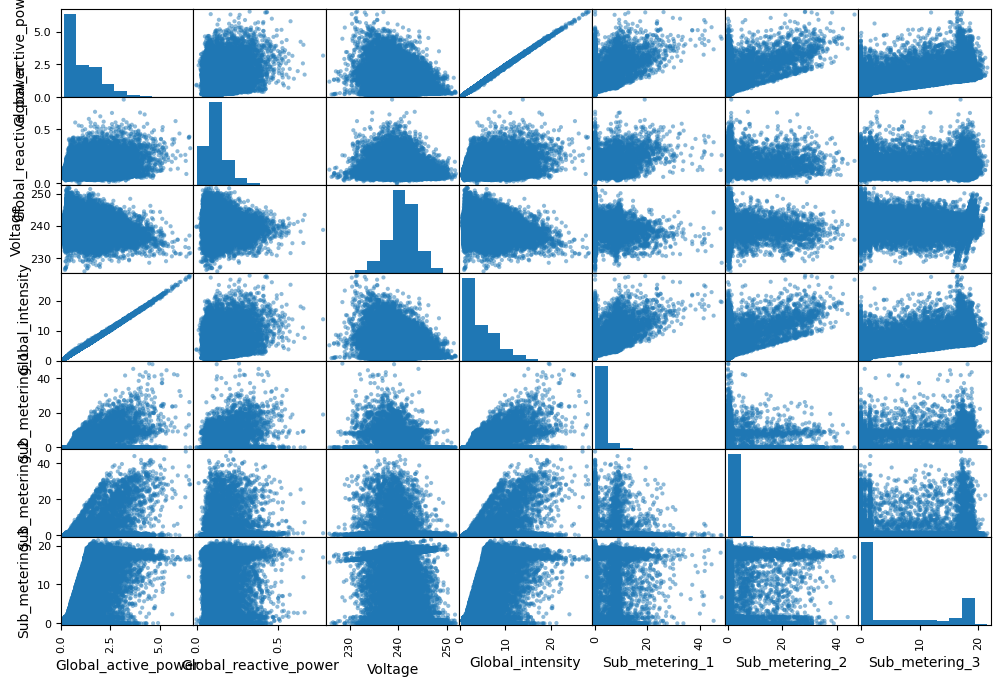

In [23]:
pd.plotting.scatter_matrix(df, figsize=(12,8))
plt.yticks(rotation=90)
plt.show()

The correlations found in the table above could also be seen in this graph. We don't find that many linear relations outside of the ones we've already seen.

## Exploring patterns

We are looking for these kinds of patterns in the electricity consumption :
- daily patterns
- weekly patterns
- monthly/seasonal patterns
- unusual spikes
- missing data

Thus we don't need to work with the full dataset.

In [24]:
consump_data = train_set['Global_active_power']

One thing that we can note about yearly patterns, as seen in the plot under aggregated data, is that the consumption doesn't change much overall. Instead we see a seasonal trend that returns every year. The consumption always peaks around January and is the lowest around August.

### Daily patterns

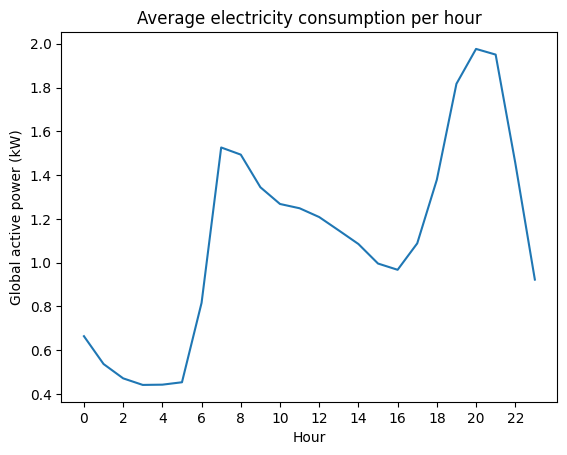

In [25]:
consump_by_hour = consump_data.groupby(consump_data.index.hour).mean()

fig, ax = plt.subplots(1,1)
ax.plot(consump_by_hour.index, consump_by_hour)
ax.set_title("Average electricity consumption per hour")
ax.set_xlabel("Hour")
ax.set_ylabel("Global active power (kW)")
ax.set_xticks(range(0,24,2))
plt.show()

We can see that more power is used during the hours that people usually are at home, i.e. in the morning and evening.

### Weekly patterns

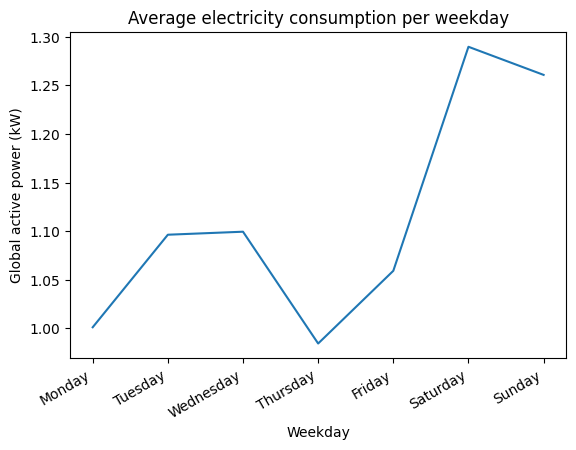

In [26]:
consump_by_weekday = consump_data.groupby(consump_data.index.day_of_week).mean()

weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, ax = plt.subplots(1,1)
ax.plot(consump_by_weekday.index, consump_by_weekday)
ax.set_title("Average electricity consumption per weekday")
ax.set_xlabel("Weekday")
ax.set_ylabel("Global active power (kW)")
ax.set_xticks(range(0, len(weekdays)))
ax.set_xticklabels(weekdays)
fig.autofmt_xdate()
plt.show()

It makes sense that the electrical consumption is higher in the weekends since people stay at home more.

One observation is that Tuesdays and Wednesdays havee higher electrical consumption for some reason.

### Monthly/Seasonal patterns

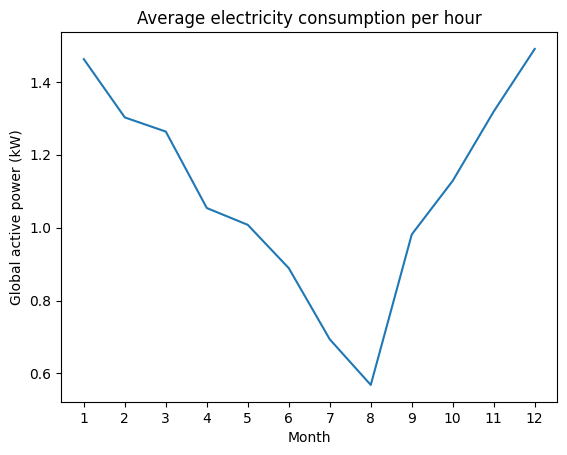

In [27]:
consump_monthly = consump_data.groupby(consump_data.index.month).mean()

fig, ax = plt.subplots(1,1)
ax.plot(consump_monthly.index, consump_monthly)
ax.set_title("Average electricity consumption per hour")
ax.set_xlabel("Month")
ax.set_ylabel("Global active power (kW)")
ax.set_xticks(range(1,13))
plt.show()

We can see that the colder months uses more energy in this house, which makes sense, since heating uses much energy.

One weird thing is that the power consumption is quite low during July and August, the warmest months in Paris. The source says that the house has a air conditioner, and they use quite a lot of electricity, but it may be uncommon for French people to use them. A quick search on Google shows that using AC in recidency is not that common in France, so that might explain the graph.

Another thing worth mentioning is that the conclusion we made about seasonal data, where we have peaks during winter and smallest in summer, is also seen here.

### Unusual spikes

We previously saw unsually low values for consumption between 2008-08-12 and 2008-08-30. Since the other values also changed in a reasonable way, the values are probably not from measurement errors. The period with low values are quite long too, so a change in consumption is reasonable.

In [28]:
train_set.describe()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,27489.000000,27489.000000,27489.000000,27489.000000,27489.000000,27489.000000,27489.000000
mean,1.112759,0.122052,240.734317,4.718512,1.162643,1.355081,6.369562
std,0.931407,0.067347,3.113839,3.900484,3.620535,4.354010,7.359915
min,0.124000,0.021033,225.834500,0.503333,0.000000,0.000000,0.000000
25%,0.332800,0.076567,238.983833,1.473333,0.000000,0.000000,0.000000
50%,0.812933,0.104800,240.887333,3.473333,0.000000,0.316667,1.616667
75%,1.615133,0.146367,242.693833,6.776667,0.000000,0.616667,14.283333
max,6.560533,0.774333,251.902000,28.383333,48.366667,46.433333,20.760000


Looking at our data again, we can see that we have a spike at 6.56. This is unusual considering that the mean is 1.1 and median is 0.8.

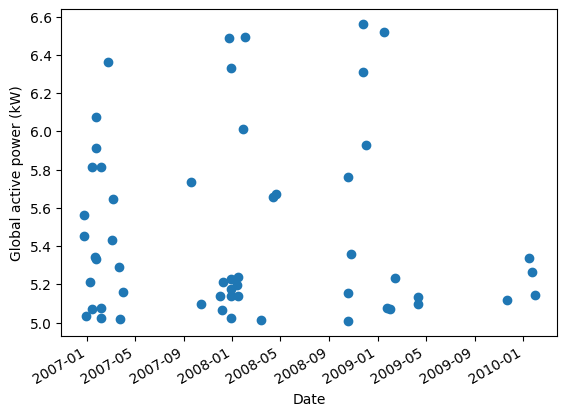

In [29]:
spikes = train_set[train_set["Global_active_power"] > 5]["Global_active_power"]

fig, ax = plt.subplots(1,1)
ax.scatter(spikes.index, spikes)
ax.set_xlabel("Date")
ax.set_ylabel("Global active power (kW)")
fig.autofmt_xdate()
plt.show()

We can see that the spikes are recurrent from the graph above. Let's zoom in on around 2009.

In [30]:
spikes_zoom = train_set[ "2008-09-01" : "2009-02-01" ]
spikes_zoom = spikes_zoom[spikes_zoom["Global_active_power"] > 5]

spikes_zoom

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2008-10-18 23:00:00,5.008167,0.359267,238.161333,21.110000,13.316667,0.133333,17.783333
2008-10-19 00:00:00,5.155500,0.334567,237.129833,21.813333,0.000000,23.066667,8.066667
2008-10-19 01:00:00,5.759067,0.408900,235.124833,24.713333,11.633333,24.533333,15.116667
2008-10-24 21:00:00,5.356867,0.264433,233.766333,22.870000,44.516667,0.000000,15.183333
2008-11-23 18:00:00,6.560533,0.324833,231.566667,28.383333,0.000000,28.333333,16.466667
2008-11-23 20:00:00,6.310567,0.263800,233.417833,27.080000,7.450000,21.116667,16.716667
2008-11-30 20:00:00,5.930500,0.136700,235.658000,25.260000,9.183333,33.216667,17.050000
2009-01-16 20:00:00,6.519633,0.431600,236.970167,27.746667,26.150000,28.200000,17.233333
2009-01-24 11:00:00,5.073400,0.407633,237.942667,21.583333,19.350000,37.516667,17.366667


Since the intensity and sub_meterings are also high when the active power is, the data makes sense.

November 23 has two spikes. Let's look at the whole day:

/tmp/ipykernel_2314/2724132158.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(range(0,24,3))


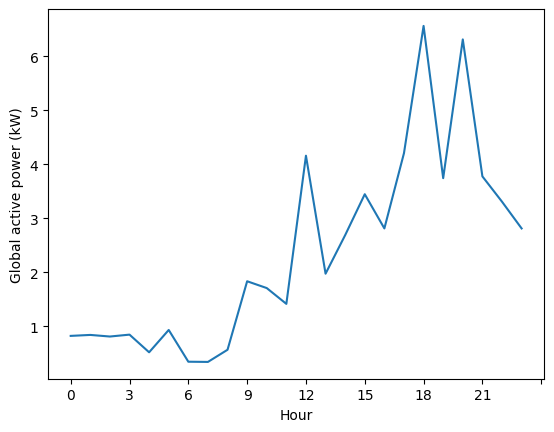

In [31]:
spike = train_set["Global_active_power"][ "2008-11-23"  ]

fig, ax = plt.subplots(1,1)
ax.plot(spike.index, spike)
ax.set_xlabel("Hour")
ax.set_ylabel("Global active power (kW)")
ax.set_xticklabels(range(0,24,3))
plt.show()

The consumption during the morning is quite normal compared to the daily pattern we've seen, but unusually high from noon. It was a Sunday though, which we also saw usually had higher consumption. So the data is probably fine and consistent.

### Missing data

Below, we can find the number missing values per day, for the days that have missing data.

In [32]:
train_set[train_set.isnull().any(axis=1)].groupby(lambda x: x.date()).size()

,0
datetime,
2007-04-28,23
2007-04-29,24
2007-04-30,14
2007-07-15,1
2009-06-13,23
2009-06-14,24
2009-06-15,7
2009-08-13,14
2010-01-12,9


In [33]:
train_set[train_set.isnull().any(axis=1)]

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2007-04-28 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-04-28 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-04-28 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-04-28 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2007-04-28 05:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2010-01-14 14:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-14 15:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-01-14 16:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Looking at both tables above, we can see that there are some small gaps in the data as well as gaps spanning at most three days. The missing data does not appear to occur in regular intervals. One other thing that was observed was that all identified gaps began between 15.00 and 05.00. In the next part, we'll try to handle these missing data.

# Clean data

Based on the patterns we saw above, we can make an imputer that takes daily and weekly patterns into consideration.

In [34]:
# Impute values based on the average from the day before & after and a week earlier and later.
def pattern_impute(dataframe):
  dataframe = dataframe.copy()

  values = [
        dataframe.shift(24 * 7),
        dataframe.shift(24),
        dataframe.shift(-24),
        dataframe.shift(-24 * 7)
  ]

  imputed = pd.concat(values).groupby(level=0, sort=False).mean()

  return dataframe.fillna(imputed)

We don't actually know if this imputer is good yet, so we'll compare it's performance with a simple median imputer and linear interpolation.

## Validate imputers

In [35]:
def simple_impute_wrapper(dataframe):
  imputer = SimpleImputer(strategy="median")

  out_array = imputer.fit_transform(dataframe)

  return pd.DataFrame( out_array, index=dataframe.index, columns=dataframe.columns )

def linear_interpolation_wrapper(dataframe):
  return dataframe.interpolate(method="linear")

In [36]:
def validate_imputation(og_df, imputation_function, n_tests=100, random_state=rs):
  rng = np.random.default_rng(random_state)
  gap_hours = [1, 3, 6, 12, 24, 24*2, 24*3]
  rmses = {}

  for gap in gap_hours:
      mses = []

      for _ in range(n_tests):
          test_df = og_df.copy()

          # Hide some values

          start = rng.integers(0, len(test_df) - gap + 1)
          hide_idx = test_df.index[start : start + gap]

          test_df.loc[hide_idx] = np.nan

          # Impute and calculate error

          imputed_df = imputation_function(test_df)

          error = og_df.loc[hide_idx] - imputed_df.loc[hide_idx]

          # Store the Mean Squared Error (MSE) for each column as a Series
          mses.append((error**2).mean())

      rmses[gap] = pd.DataFrame(mses).mean(axis=0) ** (1/2)

  return rmses

# Converts error values to how many percentage higher/lower than the baseline they are
def error_percentage_diff(error_baseline, error_compare):
  output = {}
  for gap in error_baseline:
    output[gap] = error_compare[gap] / error_baseline[gap]

  return output

In [37]:
pattern_error = validate_imputation(train_set, pattern_impute)
simple_error = validate_imputation(train_set, simple_impute_wrapper)
linear_error = validate_imputation(train_set, linear_interpolation_wrapper)

In [38]:
# How the simple imputer compares to the pattern imputer
error_percentage_diff(pattern_error, simple_error)

{1: Global_active_power      1.357766
 Global_reactive_power    1.069691
 Voltage                  1.772893
 Global_intensity         1.344255
 Sub_metering_1           0.976164
 Sub_metering_2           0.832004
 Sub_metering_3           1.344796
 dtype: float64,
 3: Global_active_power      1.318572
 Global_reactive_power    1.056970
 Voltage                  1.765623
 Global_intensity         1.316696
 Sub_metering_1           0.941761
 Sub_metering_2           0.839921
 Sub_metering_3           1.416993
 dtype: float64,
 6: Global_active_power      1.207222
 Global_reactive_power    1.203477
 Voltage                  1.736999
 Global_intensity         1.202782
 Sub_metering_1           0.903723
 Sub_metering_2           0.954194
 Sub_metering_3           1.344538
 dtype: float64,
 12: Global_active_power      1.363832
 Global_reactive_power    1.081344
 Voltage                  1.791223
 Global_intensity         1.359242
 Sub_metering_1           0.918713
 Sub_metering_2           

In [39]:
# How the linear interpolation compares to the pattern imputer
error_percentage_diff(pattern_error, linear_error)

{1: Global_active_power      0.812646
 Global_reactive_power    0.832412
 Voltage                  0.635535
 Global_intensity         0.806923
 Sub_metering_1           0.879841
 Sub_metering_2           0.984604
 Sub_metering_3           0.748076
 dtype: float64,
 3: Global_active_power      1.029613
 Global_reactive_power    0.999400
 Voltage                  0.930604
 Global_intensity         1.031055
 Sub_metering_1           1.012643
 Sub_metering_2           1.016357
 Sub_metering_3           1.067809
 dtype: float64,
 6: Global_active_power      1.098239
 Global_reactive_power    1.079672
 Voltage                  1.280622
 Global_intensity         1.097376
 Sub_metering_1           1.287075
 Sub_metering_2           1.060805
 Sub_metering_3           1.100245
 dtype: float64,
 12: Global_active_power      1.330053
 Global_reactive_power    1.083644
 Voltage                  1.649342
 Global_intensity         1.327670
 Sub_metering_1           1.039488
 Sub_metering_2           

## Evaluation imputer

The problem with the imputers mentioned above is that they access future data, which isn't possible when predicting in a realistic scenario. Thus, when we need to impute the validation and test data, we'll use another imputer:

In [40]:
# The full dataframe is used so that the validation and test set has access to the full data history
def eval_imputer(dataframe, full_df):
  dataframe = dataframe.copy()

  values = [
        full_df.shift(24 * 7),
        full_df.shift(24)
  ]

  imputed = pd.concat(values).groupby(level=0, sort=False).mean()

  return dataframe.fillna(imputed)

## Fill missing data

From the result above, we can first see that our own imputer performs better than the simple imputer for most cases, where sub-metering 1 and 2 are the only exceptions. When our pattern imputer is compared to the linear interpolation, it performs better when the missing data blocks are 6 hours or longer. For 3 hours, we see that they better or worse depending on the feature, but our imputer performs slightly better for the target variable. For missing data that is only an hour long, we see that the linear interpolation performs better.

During the exploring data chapter, we saw that all but one missing data blocks are longer than 6 hours. Thus, for simplicity, we'll use our own imputer to fill missing data in our dataset.

In [41]:
clean_train_set = pattern_impute( train_set )
clean_validation_set = eval_imputer(validation_set, df)
clean_test_set = eval_imputer(test_set, df)

# Summary of the data

We're working with time series data of the electrical consumption of a household in Paris, France. The data is minutely, but has been converted to hourly, as the prediction is going to be for the next hour.

When looking at how the features correlate with the target variable, we saw that intensity as well as the sub meterings correlated the most, while voltage had some negative correlation.

As for patterns in the data, we saw that the electrical consumption is higher during the morning and evenings, weekends and winters.

We found some unusual spikes but they were found to be reaonsable based on the surrounding data.

The missing data was filled by taking the average value of the day before & after as well as the same day a week before & after.

# Feature Engineering

We'll add features into the dataset so that the models can learn the patterns we've observed.

In [42]:
def create_features(dataframe_og):
  dataframe = dataframe_og.copy()

  target_variable = "Global_active_power"

  # Add the electrical consumption from previous times as features
  dataframe["lag_1h"] = dataframe[target_variable].shift(1)
  dataframe["lag_1day"] = dataframe[target_variable].shift(24)
  dataframe["lag_1week"] = dataframe[target_variable].shift(24*7)

  # Add the seasonal patterns
  dataframe["hour"] = dataframe.index.hour
  dataframe["day_of_week"] = dataframe.index.day_of_week
  dataframe["month"] = dataframe.index.month

  return dataframe

Adding these features introduced some missing values at the beginning of the dataset, so we'll have two remove some of them.

In [43]:
# Merge back dataset and create the new features
merged_df = pd.concat([clean_train_set, clean_validation_set, clean_test_set])
merged_df = create_features(merged_df)

clean_train_set = merged_df.iloc[:valid_cut_i]
clean_validation_set = merged_df.iloc[valid_cut_i : test_cut_i]
clean_test_set = merged_df.iloc[test_cut_i:]

# Remove the first rows with missing values
clean_train_set = clean_train_set.drop(clean_train_set.index[:24*7])

# Divide the train set into target variable and feature variables
train_X = clean_train_set.drop("Global_active_power", axis=1)
train_y = clean_train_set["Global_active_power"]

We also need a feature scaler for some of the features. A standard scaler should be enough for now.

In [44]:
scaler = StandardScaler()
scale_train_X = scaler.fit_transform(train_X)

# Building simple baselines

In [45]:
def prev_hour_baseline(X: pd.DataFrame):
  return X["lag_1h"]

def prev_day_baseline(X: pd.DataFrame):
  return X["lag_1day"]

def prev_week_baseline(X: pd.DataFrame):
  return X["lag_1week"]


# Classical ML models

The three clasical ML models we're using for this project is linear regression, random forest and gradient boosting.

In [46]:
linreg = LinearRegression().fit(scale_train_X, train_y)

In [47]:
rf_reg = RandomForestRegressor(random_state=rs).fit(scale_train_X, train_y)

In [48]:
hgb_reg = HistGradientBoostingRegressor(random_state=rs).fit(scale_train_X, train_y)

# Validating the models:

In [49]:
# Separate validation set
val_X = clean_validation_set.drop("Global_active_power", axis=1)
val_y = clean_validation_set["Global_active_power"]

# Scale validation data
scale_val_set = scaler.transform(val_X)

In [50]:
# Baselines
prev_hour_rmse = root_mean_squared_error(val_y, prev_hour_baseline(val_X) )
prev_hour_mae = mean_absolute_error(val_y, prev_hour_baseline(val_X) )

prev_day_rmse = root_mean_squared_error(val_y, prev_day_baseline(val_X) )
prev_day_mae = mean_absolute_error(val_y, prev_day_baseline(val_X) )

prev_week_rmse = root_mean_squared_error(val_y, prev_week_baseline(val_X) )
prev_week_mae = mean_absolute_error(val_y, prev_week_baseline(val_X) )

In [51]:
# Linear regression
lin_pred = linreg.predict(scale_val_set)
lin_rmse = root_mean_squared_error(val_y, lin_pred)
lin_mae = mean_absolute_error(val_y, lin_pred)

In [52]:
# Random Forest
rf_pred = rf_reg.predict(scale_val_set)
rf_rmse = root_mean_squared_error(val_y, rf_pred)
rf_mae = mean_absolute_error(val_y, rf_pred)

In [53]:
# Histogram-based Gradient Boosting
hgb_pred = hgb_reg.predict(scale_val_set)
hgb_rmse = root_mean_squared_error(val_y, hgb_pred)
hgb_mae = mean_absolute_error(val_y, hgb_pred)

## Comparing the models

In [54]:
models_used = ["Previous hour", "Previous day", "Previous week", "Linear Regression", "Random Forest", "Histogram-based Gradient Boosting"]

result = {
    "RMSE": [prev_hour_rmse, prev_day_rmse, prev_week_rmse, lin_rmse, rf_rmse, hgb_rmse],
    "MAE": [prev_hour_mae, prev_day_mae, prev_week_mae, lin_mae, rf_mae, hgb_mae]
}

first_val_result = pd.DataFrame(result, index=models_used)

Conclusion:
- All of the classical ML models outpeformed the baselines
- The linear regression had the lowest RMSE
- The HGB had the lowest MAE

This indicates that the linear regression has less large outlier errors than the HGB, but the linear regression has worse average performance across normal data points. Linear regression has around 5% lower RMSE and 6% higher MAE than the HGB.

Since the difference between the linear regression model and HGB model isn't enormous, a single validation doesn't tell if the difference is robust. To see which model is consistently better, we'll use expanding window validation.

## Expanding window validation

In [55]:
def expanding_window_validation(dataframe, model_pipeline, nr_splits=5):
  target_variable = "Global_active_power"
  dataframe = dataframe.copy()

  results = {}

  tscv = TimeSeriesSplit(n_splits=nr_splits)
  for i, (train_index, test_index) in enumerate(tscv.split(dataframe)):
    train_data = dataframe.iloc[train_index]
    test_data = dataframe.iloc[test_index]

    X = train_data.drop(target_variable, axis=1)
    y = train_data[target_variable]
    reg = model_pipeline.fit(X, y)

    X = test_data.drop(target_variable, axis=1)
    y_true = test_data[target_variable]
    y_pred = reg.predict(X)

    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    results[f"Fold {i+1}"] = {
        "RMSE": rmse,
        "MAE": mae
    }

  return results

In [56]:
# Getting the full training dataset
full_train_set = pd.concat([clean_train_set, clean_validation_set])

In [57]:
lin_pipe = make_pipeline( StandardScaler(), LinearRegression() )

lin_errors = expanding_window_validation(full_train_set, lin_pipe)

In [58]:
hgb_pipe = make_pipeline( StandardScaler(), HistGradientBoostingRegressor(random_state=rs) )

hgb_errors = expanding_window_validation(full_train_set, hgb_pipe)

In [59]:
forest_pipe = make_pipeline( StandardScaler(), RandomForestRegressor(random_state=rs) )

forest_errors = expanding_window_validation(full_train_set, forest_pipe)

Now we can calculate how many percentages higher/lower the errors from the HGB model are compared to the linear model

In [60]:
hgb_comparison = {}
for fold, l_errors in lin_errors.items():
  h_errors = hgb_errors[fold]
  hgb_comparison[fold] = {
      "RMSE ratio": h_errors["RMSE"] / l_errors["RMSE"],
      "MAE ratio": h_errors["MAE"] / l_errors["MAE"]
  }
hgb_comparison

{'Fold 1': {'RMSE ratio': 2.058372196606985, 'MAE ratio': 1.195175713439219},
 'Fold 2': {'RMSE ratio': 1.1260671855625044, 'MAE ratio': 1.0248069537603073},
 'Fold 3': {'RMSE ratio': 1.8640361810866872, 'MAE ratio': 0.9790354161917425},
 'Fold 4': {'RMSE ratio': 1.1963961977655884, 'MAE ratio': 0.8894341322841569},
 'Fold 5': {'RMSE ratio': 1.1842373735430238, 'MAE ratio': 0.9941242551953973}}

In [61]:
forest_comparison = {}
for fold, l_errors in lin_errors.items():
  f_errors = forest_errors[fold]
  forest_comparison[fold] = {
      "RMSE ratio": f_errors["RMSE"] / l_errors["RMSE"],
      "MAE ratio": f_errors["MAE"] / l_errors["MAE"]
  }
forest_comparison

{'Fold 1': {'RMSE ratio': 1.2729601209289059, 'MAE ratio': 1.1281760436339652},
 'Fold 2': {'RMSE ratio': 1.0910545040845152, 'MAE ratio': 1.061773474802744},
 'Fold 3': {'RMSE ratio': 0.9514551745513594, 'MAE ratio': 0.8960631052884354},
 'Fold 4': {'RMSE ratio': 0.9887111260151484, 'MAE ratio': 0.9323538993356505},
 'Fold 5': {'RMSE ratio': 1.0316800005500146, 'MAE ratio': 0.9584205700511491}}

Conclusions:
- HGB always has a higher RMSE than the linear regression. Their MAE are quite similar.
  - We can still see that the HGB is making few large errors
- Random forest has a similar RMSE and MAE to linear regression. The first is slightly higher, and the MAE is slightly lower.
  - Linear regression performs better on the first two folds, but random forest performs well in the later folds.

# Error analysis

With the validation above we saw the performances of the three different classical models. HGB, with it's higher RSME, indicates that it has difficulties with certain observations. The random forest and HGB are less interpretable than the linear regression, which relatively performed well, so we'll use linear regression for our deeper error analysis.

First, let's put together our error data:

In [62]:
error_results = pd.DataFrame({
    "Actual": val_y,
    "Prediction": lin_pred
})

error_results["Error"] = error_results["Actual"] - error_results["Prediction"]
error_results["Absolute error"] = abs(error_results["Error"])
error_results["Squared error"] = error_results["Error"]**2

## Worst predictions

The 20 worst predictions:

In [63]:
worst_errors = error_results.sort_values("Absolute error", ascending=False).head(20)
worst_errors

,Actual,Prediction,Error,Absolute error,Squared error
datetime,,,,,
2010-06-21 14:00:00,1.539500,1.757385,-0.217885,0.217885,0.047474
2010-05-19 20:00:00,2.320100,2.521244,-0.201144,0.201144,0.040459
2010-06-11 19:00:00,1.751667,1.912875,-0.161209,0.161209,0.025988
2010-06-03 19:00:00,1.247567,1.408369,-0.160803,0.160803,0.025858
2010-06-25 12:00:00,1.961367,2.117095,-0.155729,0.155729,0.024251
2010-06-05 16:00:00,2.077067,2.230338,-0.153272,0.153272,0.023492
2010-06-11 13:00:00,1.320533,1.449487,-0.128953,0.128953,0.016629
2010-03-11 20:00:00,3.485733,3.613845,-0.128112,0.128112,0.016413
2010-03-23 15:00:00,2.227000,2.338557,-0.111557,0.111557,0.012445


In [64]:
data_worst_errors = clean_validation_set.loc[ worst_errors.index ]

# Worst time
print(data_worst_errors["hour"].value_counts())
print("---")

# Worst errors are between 12:00 and 04:00 (afternoon/evening/night)
print("Worst errors are between 12:00 and 04:00 (afternoon/evening/night)")
print(( (data_worst_errors["hour"] > 12) | (data_worst_errors["hour"] < 4) ).value_counts() )
print("---")

# Worst month

print(data_worst_errors["month"].value_counts())
print("---")

# Worst day of the week
print("Day of the week")
worst_days = data_worst_errors["day_of_week"].value_counts(sort = False)
worst_days = worst_days.sort_index()
worst_days.index = weekdays
worst_days = worst_days.sort_values(ascending = False)
print(worst_days)

hour
19    3
17    3
11    3
16    2
20    2
18    2
14    1
15    1
13    1
12    1
0     1
Name: count, dtype: int64
---
Worst errors are between 12:00 and 04:00 (afternoon/evening/night)
hour
True     16
False     4
Name: count, dtype: int64
---
month
6    11
3     3
2     3
5     2
4     1
Name: count, dtype: int64
---
Day of the week
Saturday     5
Friday       4
Sunday       3
Wednesday    2
Tuesday      2
Monday       2
Thursday     2
Name: count, dtype: int64


Based on this, we can see that the worst errors happen after 12:00, during June and during weekends as well as Fridays.

In [65]:
# Check for sudden consumption differences

sudden_differences = (data_worst_errors["Global_active_power"] - data_worst_errors["lag_1h"])
sudden_differences = pd.concat( [sudden_differences, error_results.loc[sudden_differences.index]["Absolute error"] ], axis=1 )
sudden_differences = sudden_differences.rename(columns={0: "Consumption change", "Absolute error": "Prediction absolute error"})
sudden_differences["Relative change (%)"] = sudden_differences["Consumption change"] / data_worst_errors["Global_active_power"] * 100
sudden_differences = sudden_differences.sort_values("Relative change (%)", ascending=False, key=abs)
sudden_differences = sudden_differences.iloc[:, [0, 2, 1]]
sudden_differences

,Consumption change,Relative change (%),Prediction absolute error
datetime,,,
2010-03-23 16:00:00,-1.209167,-118.798101,0.100848
2010-06-11 17:00:00,-0.584700,-112.391875,0.104483
2010-02-21 11:00:00,3.840433,75.438700,0.090892
2010-06-11 19:00:00,1.278600,72.993340,0.161209
2010-06-03 19:00:00,0.848600,68.020413,0.160803
2010-06-21 14:00:00,0.879200,57.109451,0.217885
2010-05-19 20:00:00,1.249133,53.839633,0.201144
2010-06-05 16:00:00,0.869900,41.881179,0.153272
2010-05-31 19:00:00,-0.445633,-35.039576,0.094285


In [66]:
(abs(sudden_differences["Relative change (%)"]) > 20).sum()

np.int64(14)

We see that 14 out of the 20 worst errors have a sudden change in consumption by 20%. So most of the large errors also have a sudden large change in consumption. Therefore, it can be worth to try adding a new feature that looks at the past standard deviation.

## Trying a new feature

In [67]:
# Adding the new feature
full_train_set_sd = merged_df.iloc[:test_cut_i].copy()
full_train_set_sd["Rolling SD"] = full_train_set_sd["Global_active_power"].rolling(window=3).std().shift(1) # We need the shift to avoid data leakage
full_train_set_sd = full_train_set_sd.drop(full_train_set_sd.index[:24*7])

In [68]:
lin_pipe_new = make_pipeline( StandardScaler(), LinearRegression() )

lin_errors_sd = expanding_window_validation(full_train_set_sd, lin_pipe_new)

In [69]:
new_feature_comparison = {}
for fold, l_errors in lin_errors.items():
  f_errors = lin_errors_sd[fold]
  new_feature_comparison[fold] = {
      "RMSE ratio": f_errors["RMSE"] / l_errors["RMSE"],
      "MAE ratio": f_errors["MAE"] / l_errors["MAE"]
  }
new_feature_comparison

{'Fold 1': {'RMSE ratio': 0.9984385329655553, 'MAE ratio': 1.000123340624929},
 'Fold 2': {'RMSE ratio': 1.0015876166683215, 'MAE ratio': 1.0018343323566905},
 'Fold 3': {'RMSE ratio': 0.997868056665962, 'MAE ratio': 0.997753740853303},
 'Fold 4': {'RMSE ratio': 1.0026866151869707, 'MAE ratio': 1.0042619855028707},
 'Fold 5': {'RMSE ratio': 0.9985214355568137, 'MAE ratio': 0.9974232816531471}}

It seems like adding the new feature doesn't do any remarkable difference for the linear regression.

## Compare worst predictions

When validating our models, we saw that HGB always has a higher RMSE than the linear regression. Thus, it would be interesting to look at HGB's largest errors and compare them to the linear regression's.

In [70]:
hgb_error_results = pd.DataFrame({
    "Actual": val_y,
    "Prediction": hgb_pred
})

hgb_error_results["Error"] = hgb_error_results["Actual"] - hgb_error_results["Prediction"]
hgb_error_results["Absolute error"] = abs(hgb_error_results["Error"])
hgb_error_results["Squared error"] = hgb_error_results["Error"]**2
hgb_worst_errors = hgb_error_results.sort_values("Absolute error", ascending=False).head(20)
hgb_worst_errors[:10]

,Actual,Prediction,Error,Absolute error,Squared error
datetime,,,,,
2010-02-15 20:00:00,4.619633,4.939813,-0.320180,0.320180,0.102515
2010-02-21 14:00:00,4.638200,4.924471,-0.286271,0.286271,0.081951
2010-06-21 14:00:00,1.539500,1.754844,-0.215344,0.215344,0.046373
2010-05-19 20:00:00,2.320100,2.533587,-0.213487,0.213487,0.045577
2010-06-11 19:00:00,1.751667,1.938144,-0.186477,0.186477,0.034774
2010-06-03 19:00:00,1.247567,1.419412,-0.171845,0.171845,0.029531
2010-06-25 12:00:00,1.961367,2.120451,-0.159084,0.159084,0.025308
2010-03-11 20:00:00,3.485733,3.639664,-0.153931,0.153931,0.023695
2010-04-11 21:00:00,3.883133,4.035159,-0.152026,0.152026,0.023112


Comparing the absolute errors:

In [71]:
worst_errors[:5]

,Actual,Prediction,Error,Absolute error,Squared error
datetime,,,,,
2010-06-21 14:00:00,1.539500,1.757385,-0.217885,0.217885,0.047474
2010-05-19 20:00:00,2.320100,2.521244,-0.201144,0.201144,0.040459
2010-06-11 19:00:00,1.751667,1.912875,-0.161209,0.161209,0.025988
2010-06-03 19:00:00,1.247567,1.408369,-0.160803,0.160803,0.025858
2010-06-25 12:00:00,1.961367,2.117095,-0.155729,0.155729,0.024251


As we can see, the seven worst errors for HGB are comparable to the four worst errors of the linear regression. Let's count how many "meaningful" errors both models have:

In [72]:
# HGB
print("HGB, number of 'meaningful' errors:", hgb_error_results[hgb_error_results["Absolute error"] > 0.01]["Absolute error"].count() )
print("Linear regression, number of 'meaningful' errors:", error_results[error_results["Absolute error"] > 0.01]["Absolute error"].count() )

HGB, number of 'meaningful' errors: 1578
Linear regression, number of 'meaningful' errors: 1759


This indicates that the linear regression has worse average performance, which we also concluded with the MAE result from the validation chapter.

So HGB performs worse due to a "small" number of more extreme forecasting errors.

## Which features matter the most?

### Linear regression:

In [73]:
pd.DataFrame({
    "feature": val_X.columns,
    "coefficient": linreg.coef_
}).sort_values("coefficient", key=abs, ascending=False)

,feature,coefficient
2,Global_intensity,0.929395
1,Voltage,0.014212
0,Global_reactive_power,-0.012903
5,Sub_metering_3,0.011920
4,Sub_metering_2,-0.004230
3,Sub_metering_1,-0.003711
6,lag_1h,0.002879
9,hour,0.001578
11,month,0.000677
8,lag_1week,0.000631


This is interesting because this shows that the model almost only uses the intensity to determine the consumption. The consumption of one day before even has a negative coefficient, altough it is almost 0. Two of the sub-meterings are also negative which is quite weird, since we know that they a part of the total consumption.

Seeing these values, it makes sense that adding a rolling standard deviation feature does not make much difference for the performance. This might not be true for other models though, especially the HGB.

Note: we normalized the coefficient values by using our standard scaler.

### Random Forest

In [74]:
pd.DataFrame({
    "feature": val_X.columns,
    "Mean accuracy decrease": permutation_importance(rf_reg, scale_val_set, val_y, random_state=rs)['importances_mean']
}).sort_values("Mean accuracy decrease", key=abs, ascending=False)

,feature,Mean accuracy decrease
2,Global_intensity,2.032979
0,Global_reactive_power,0.000677
1,Voltage,0.000637
5,Sub_metering_3,0.000190
3,Sub_metering_1,0.000086
4,Sub_metering_2,0.000030
9,hour,0.000015
11,month,0.000010
6,lag_1h,0.000006
10,day_of_week,0.000005


### HGB

In [75]:
pd.DataFrame({
    "feature": val_X.columns,
    "Mean accuracy decrease": permutation_importance(hgb_reg, scale_val_set, val_y, random_state=rs)['importances_mean']
}).sort_values("Mean accuracy decrease", key=abs, ascending=False)

,feature,Mean accuracy decrease
2,Global_intensity,2.007067
1,Voltage,0.000703
0,Global_reactive_power,0.000543
5,Sub_metering_3,0.000356
9,hour,0.000063
4,Sub_metering_2,0.000044
7,lag_1day,-0.000041
8,lag_1week,0.000036
11,month,0.000021
10,day_of_week,-0.000011


As we can see from the tables above, almost only the intensity is actually used by all three models. The voltage and reactive power are also highly used, which makes sense since consumption is roughly intensity times voltage.

One mistake that has been done so far is that we've technically leaked data for the time t when we're predicting the consumption for the same time t. For a forecast, having the previous hour's value would be more realistic. We thus need to change our dataset.

With everything in consideration, two things now makes sense:
- We saw that the largest errors were during weekends and during the night. This was most likely because the models didn't consider the day of the week and the time much, as seen in the tables above.
- The linear regression worked so good because consumption and intensity has an extremely high linear correlation, which we discovered during the data exploration chapter.

# Redoing with the fixed dataset

## Fixing the dataset

As described above, we have leaked data from the time we're predicting, such as the reactive power, voltage and intensity. Thus, we need to shift these values so that they instead become "lag" values. Thereafter, we can validate our models again and repeat our error analysis.

In [76]:
# Fix leaking features

leaking_features = list(df.columns)
leaking_features.remove('Global_active_power')

new_full_df = merged_df.copy()
new_full_df[leaking_features] = new_full_df[leaking_features].shift(1)
new_full_df = new_full_df.rename(columns={
    leaking_features[0]: "Prev_reactive_power",
    leaking_features[1]: "Prev_voltage",
    leaking_features[2]: "Prev_intensity",
    leaking_features[3]: "Prev_sub_metering_1",
    leaking_features[4]: "Prev_sub_metering_2",
    leaking_features[5]: "Prev_sub_metering_3"
})

In [77]:
# Divide the dataset

new_train_set = new_full_df.iloc[:valid_cut_i]
new_validation_set = new_full_df.iloc[valid_cut_i : test_cut_i]
new_test_set = new_full_df.iloc[test_cut_i:]

# Remove the first rows with missing values
new_train_set = new_train_set.drop(new_train_set.index[:24*7])

new_full_train_set = pd.concat([new_train_set, new_validation_set])

# Divide the train set into target variable and feature variables
train_X = new_train_set.drop("Global_active_power", axis=1)
scale_train_X = scaler.fit_transform(train_X)
train_y = new_train_set["Global_active_power"]

# Divide the test set into target variable and feature variables
val_X = new_validation_set.drop("Global_active_power", axis=1)
scale_val_X = scaler.transform(val_X)
val_y = new_validation_set["Global_active_power"]

## Retraining and revalidating the models

Training:

In [78]:
linreg = LinearRegression().fit(scale_train_X, train_y)
rf_reg = RandomForestRegressor(random_state=rs).fit(scale_train_X, train_y)
hgb_reg = HistGradientBoostingRegressor(random_state=rs).fit(scale_train_X, train_y)

Validating:

In [79]:
# Baselines
prev_hour_rmse = root_mean_squared_error(val_y, prev_hour_baseline(val_X) )
prev_hour_mae = mean_absolute_error(val_y, prev_hour_baseline(val_X) )

prev_day_rmse = root_mean_squared_error(val_y, prev_day_baseline(val_X) )
prev_day_mae = mean_absolute_error(val_y, prev_day_baseline(val_X) )

prev_week_rmse = root_mean_squared_error(val_y, prev_week_baseline(val_X) )
prev_week_mae = mean_absolute_error(val_y, prev_week_baseline(val_X) )

# Linear regression
lin_pred = linreg.predict(scale_val_X)
lin_rmse = root_mean_squared_error(val_y, lin_pred)
lin_mae = mean_absolute_error(val_y, lin_pred)

# Random Forest
rf_pred = rf_reg.predict(scale_val_X)
rf_rmse = root_mean_squared_error(val_y, rf_pred)
rf_mae = mean_absolute_error(val_y, rf_pred)

# Histogram-based Gradient Boosting
hgb_pred = hgb_reg.predict(scale_val_X)
hgb_rmse = root_mean_squared_error(val_y, hgb_pred)
hgb_mae = mean_absolute_error(val_y, hgb_pred)

Comparing the models:

In [80]:
models_used = ["Previous hour", "Previous day", "Previous week", "Linear Regression", "Random Forest", "Histogram-based Gradient Boosting"]

result = {
    "RMSE": [prev_hour_rmse, prev_day_rmse, prev_week_rmse, lin_rmse, rf_rmse, hgb_rmse],
    "MAE": [prev_hour_mae, prev_day_mae, prev_week_mae, lin_mae, rf_mae, hgb_mae]
}

pd.DataFrame(result, index=models_used)

,RMSE,MAE
Previous hour,0.616392,0.405790
Previous day,0.823455,0.575638
Previous week,0.819344,0.573124
Linear Regression,0.528261,0.380882
Random Forest,0.490455,0.341823
Histogram-based Gradient Boosting,0.476782,0.330759


In [81]:
# The result we received with the leaking dataset
first_val_result

,RMSE,MAE
Previous hour,0.616392,0.405790
Previous day,0.823455,0.575638
Previous week,0.819344,0.573124
Linear Regression,0.020133,0.013616
Random Forest,0.020901,0.013155
Histogram-based Gradient Boosting,0.021196,0.012756


Now, this is an interesting result. Fixing the dataset so that the models only have access to past data has given us a totally different result. Conclusions:
- All of the classical ML models still outpeformed the baselines
- The linear regression now has the highest RMSE **and** MAE out of all the three classical ML models.
- HGB has the lowest RMSE **and** MAE
- The RMSE and MAE are higher for all three ML models, which is reasonable since they previously could basically cheat their way to a good answer by using the current intensity and voltage.

The RMSE and MAE of RF and HGB are quite similar though, so let's see if the HGB consistently performs better.

In [82]:
lin_errors = expanding_window_validation(new_full_train_set, lin_pipe)
forest_errors = expanding_window_validation(new_full_train_set, forest_pipe)
hgb_errors = expanding_window_validation(new_full_train_set, hgb_pipe)

In [83]:
def error_ratio(baseline_errors, compare_errors):
  ratios = {"RMSE ratio" : [], "MAE ratio" : []}

  for fold, base_e in baseline_errors.items():
    compare_e = compare_errors[fold]
    ratios["RMSE ratio"].append( compare_e["RMSE"] / base_e["RMSE"] )
    ratios["MAE ratio"].append( compare_e["MAE"] / base_e["MAE"] )

  return {"RMSE ratio": np.array(ratios["RMSE ratio"]), "MAE ratio" : np.array(ratios["MAE ratio"])}

lin_RF_e_ratios = error_ratio(lin_errors, forest_errors)
lin_HGB_e_ratios = error_ratio(lin_errors, hgb_errors)

expanding_window_result2 = pd.DataFrame({
    "RMSE ratio - HGB / linear": lin_HGB_e_ratios["RMSE ratio"],
    "MAE ratio - HGB / linear": lin_HGB_e_ratios["MAE ratio"],
    "RMSE ratio - RF / linear": lin_RF_e_ratios["RMSE ratio"],
    "MAE ratio - RF / linear": lin_RF_e_ratios["MAE ratio"],
    "RMSE ratio - HGB / RF": lin_HGB_e_ratios["RMSE ratio"] / lin_RF_e_ratios["RMSE ratio"],
    "MAE ratio - HGB / RF": lin_HGB_e_ratios["MAE ratio"] / lin_RF_e_ratios["MAE ratio"]
})
expanding_window_result2.index.name = "Fold"
expanding_window_result2

,RMSE ratio - HGB / linear,MAE ratio - HGB / linear,RMSE ratio - RF / linear,MAE ratio - RF / linear,RMSE ratio - HGB / RF,MAE ratio - HGB / RF
Fold,,,,,,
0,0.932690,0.932592,0.952983,0.964697,0.978705,0.966720
1,0.950523,1.018437,0.990112,1.078026,0.960015,0.944724
2,0.895858,0.869661,0.930015,0.912054,0.963273,0.953520
3,0.889601,0.855750,0.938575,0.910704,0.947821,0.939657
4,0.892036,0.860145,0.921149,0.895830,0.968395,0.960165


The main take away from this table is that HGB always has lower RMSE and MAE than RF for our data, and almost always lower values when compared to linear regression. The MAE is slightly lower for the linear regression in one early fold, but otherwise much higher.

We can therefore say that the HGB performs best for our data.

## Redoing error analysis

The analysis will be done on HGB since it performed the best on both metrics.

### Worst predictions

In [84]:
new_error_results = pd.DataFrame({
    "Actual": val_y,
    "Prediction": hgb_pred
})

new_error_results["Error"] = new_error_results["Actual"] - new_error_results["Prediction"]
new_error_results["Absolute error"] = abs(new_error_results["Error"])
new_error_results["Squared error"] = new_error_results["Error"]**2
new_worst_errors = new_error_results.sort_values("Absolute error", ascending=False).head(20)
worst_performing_data = new_validation_set.loc[ new_worst_errors.index ]

In [85]:
# Worst time
print(worst_performing_data["hour"].value_counts())
print("---")

# Worst errors are between 12:00 and 04:00 (afternoon/evening/night)
print("Worst errors are between 12:00 and 04:00 (afternoon/evening/night)")
print(( (worst_performing_data["hour"] > 12) | (worst_performing_data["hour"] < 4) ).value_counts() )
print("---")

# Worst month

print(worst_performing_data["month"].value_counts())
print("---")

# Worst day of the week
worst_days = worst_performing_data["day_of_week"].value_counts()
worst_days = worst_days.rename(index={
    0: weekdays[0],
    1: weekdays[1],
    2: weekdays[2],
    3: weekdays[3],
    4: weekdays[4],
    5: weekdays[5],
    6: weekdays[6]
})

print(worst_days)

hour
12    4
17    3
19    3
11    2
10    2
21    2
14    1
15    1
0     1
20    1
Name: count, dtype: int64
---
Worst errors are between 12:00 and 04:00 (afternoon/evening/night)
hour
True     12
False     8
Name: count, dtype: int64
---
month
4    5
2    4
3    4
5    4
6    2
7    1
Name: count, dtype: int64
---
day_of_week
Sunday       6
Saturday     5
Wednesday    3
Monday       3
Friday       2
Thursday     1
Name: count, dtype: int64


We see that the largest errors still mostly are in the evening and during weekends. But overall, the errors are more evenly spread out compared to our first analysis.

### Trying a new feature

We'll check for sudden differences for the worst errors

In [86]:
sudden_differences = (worst_performing_data["Global_active_power"] - worst_performing_data["lag_1h"])
sudden_differences = pd.concat( [sudden_differences, new_error_results.loc[sudden_differences.index]["Absolute error"] ], axis=1 )
sudden_differences = sudden_differences.rename(columns={0: "Consumption change", "Absolute error": "Prediction absolute error"})
sudden_differences["Relative change (%)"] = sudden_differences["Consumption change"] / worst_performing_data["Global_active_power"] * 100
sudden_differences = sudden_differences.sort_values("Relative change (%)", ascending=False, key=abs)
sudden_differences = sudden_differences.iloc[:, [0, 2, 1]]
(abs(sudden_differences["Relative change (%)"]) > 48).sum()

np.int64(19)

We see that 19 out of the 20 worst errors have a sudden change in consumption by 48%. Therefore, it can be worth to try adding a new feature that looks at the past standard deviation again.

In [87]:
# Adding the new feature
new_full_train_set_sd = new_full_df.iloc[:test_cut_i].copy()
new_full_train_set_sd["Rolling SD"] = new_full_train_set_sd["Global_active_power"].rolling(window=3).std().shift(1)
new_full_train_set_sd = new_full_train_set_sd.drop(new_full_train_set_sd.index[:24*7])

hgb_pipe_sd = make_pipeline( StandardScaler(), HistGradientBoostingRegressor(random_state=rs) )

hgb_errors_sd = expanding_window_validation(new_full_train_set_sd, hgb_pipe_sd)

error_ratio(hgb_errors, hgb_errors_sd)

{'RMSE ratio': array([0.99606574, 1.0365173 , 0.9931671 , 1.00106294, 0.99530682]),
 'MAE ratio': array([0.9897478 , 1.06218634, 0.99140642, 0.9991991 , 0.99671443])}

We see that adding the feature doesn't make much difference unfortunately. Testing other methods to handle these sudden differences should be worth it. It can also be that the other features already take most sudden changes into consideration. Anyhow, let's look at the features that matters the most first.

### Most important features

In [88]:
pd.DataFrame({
    "feature": val_X.columns,
    "Mean accuracy decrease": permutation_importance(hgb_reg, scale_val_X, val_y, random_state=rs)['importances_mean']
}).sort_values("Mean accuracy decrease", key=abs, ascending=False)

,feature,Mean accuracy decrease
2,Prev_intensity,0.742469
9,hour,0.140804
6,lag_1h,0.127430
5,Prev_sub_metering_3,0.099876
3,Prev_sub_metering_1,0.027288
4,Prev_sub_metering_2,0.022795
10,day_of_week,0.011038
7,lag_1day,0.007728
0,Prev_reactive_power,0.007270
8,lag_1week,0.006191


One intetersting observation is that the previous hour's intensity is regarded as more important than the actual previous hour's consumption. This time, the voltage is almost regarded useless in comparison to the intensity. It's also interesting that the hour of the day is regarded as the second most important feature, while the month is one of the least important features.

We've seen that the rolling standard deviation doesn't change the RMSE and MAE metrics much, but how important is it regarded?

In [89]:
X_temp_train = new_full_train_set_sd.drop("Global_active_power", axis=1)
y_temp_train = new_full_train_set_sd['Global_active_power']

X_temp_val = X_temp_train[valid_cut_i:]
y_temp_val = y_temp_train[valid_cut_i:]

X_temp_train = X_temp_train[:valid_cut_i]
y_temp_train = y_temp_train[:valid_cut_i]
hgb_pipe_sd.fit(X_temp_train, y_temp_train)

pd.DataFrame({
    "feature": X_temp_val.columns,
    "Mean accuracy decrease": permutation_importance(hgb_pipe_sd, X_temp_val, y_temp_val, random_state=rs)['importances_mean']
}).sort_values("Mean accuracy decrease", key=abs, ascending=False)

,feature,Mean accuracy decrease
2,Prev_intensity,0.700869
9,hour,0.131933
6,lag_1h,0.129099
5,Prev_sub_metering_3,0.093042
3,Prev_sub_metering_1,0.032768
4,Prev_sub_metering_2,0.025470
12,Rolling SD,0.012549
0,Prev_reactive_power,0.011861
10,day_of_week,0.011740
8,lag_1week,0.007529


So rolling SD was ranked in the middle in terms of importance, so the features below it probably change the metrics even less than rolling SD. We saw that rolling SD improved the metrics by less than 1%.

Another observation is that prev_reactive_power is ranked higher than day_of_week this time, and lag_1week is higher than lag_1day.

### Try removing a feature

Considering that the previous hour's intensity is regarded as the most important feature, it would be interesting to see how the model performs without this feature.

In [90]:
no_intensity_train_set = pd.concat([new_train_set, new_validation_set])
no_intensity_train_set = no_intensity_train_set.drop("Prev_intensity", axis=1)

hgb_pipe_no_intensity = make_pipeline( StandardScaler(), HistGradientBoostingRegressor(random_state=rs) )

hgb_errors_no_intensity = expanding_window_validation(no_intensity_train_set, hgb_pipe_no_intensity)

error_ratio(hgb_errors, hgb_errors_no_intensity)

{'RMSE ratio': array([1.00332545, 0.99923232, 0.99300911, 1.00071415, 1.00127323]),
 'MAE ratio': array([1.00755084, 0.98902273, 0.99304673, 0.99115738, 1.0049825 ])}

So the metrics do not change much even without the intensity feature, which is interesting, considering that it was regarded as the most important feature previously. Let's see the feature importances now.

In [91]:
X_temp_train = no_intensity_train_set.drop("Global_active_power", axis=1)
y_temp_train = no_intensity_train_set['Global_active_power']

X_temp_val = X_temp_train[valid_cut_i:]
y_temp_val = y_temp_train[valid_cut_i:]

X_temp_train = X_temp_train[:valid_cut_i]
y_temp_train = y_temp_train[:valid_cut_i]
hgb_pipe_no_intensity.fit(X_temp_train, y_temp_train)

pd.DataFrame({
    "feature": X_temp_val.columns,
    "Mean accuracy decrease": permutation_importance(hgb_pipe_no_intensity, X_temp_val, y_temp_val, random_state=rs)['importances_mean']
}).sort_values("Mean accuracy decrease", key=abs, ascending=False)

,feature,Mean accuracy decrease
5,lag_1h,1.254993
8,hour,0.147915
4,Prev_sub_metering_3,0.097179
3,Prev_sub_metering_2,0.027836
2,Prev_sub_metering_1,0.027382
9,day_of_week,0.012263
0,Prev_reactive_power,0.008686
6,lag_1day,0.008052
7,lag_1week,0.007634
10,month,0.001103


This indicates that the intensity feature is important for the model's strategy, but it is not essential for overall prediction performance. The feature can be partly substitued by the other features.

What if we try removing all of the feature we fixed for the dataset?

In [92]:
try_remove = ["Prev_reactive_power", "Prev_voltage", "Prev_intensity", "Prev_sub_metering_1", "Prev_sub_metering_2", "Prev_sub_metering_3"]
test_train_set = pd.concat([new_train_set, new_validation_set])
test_train_set = test_train_set.drop(try_remove, axis=1)

hgb_pipe_test = make_pipeline( StandardScaler(), HistGradientBoostingRegressor(random_state=rs) )

hgb_errors_test = expanding_window_validation(test_train_set, hgb_pipe_test)

error_ratio(hgb_errors, hgb_errors_test)

{'RMSE ratio': array([1.07114963, 0.99000492, 1.06062403, 1.03962276, 1.04163095]),
 'MAE ratio': array([1.08690591, 0.89571052, 1.06121527, 1.04660831, 1.04779133])}

So the performance is roughly around 3.5% worse. Let's try just removing intensity, Prev_reactive_power and Prev_voltage since the last two were ranked quite low in importance.

In [93]:
try_remove = ["Prev_reactive_power", "Prev_voltage", "Prev_intensity"]
test_train_set = pd.concat([new_train_set, new_validation_set])
test_train_set = test_train_set.drop(try_remove, axis=1)

hgb_pipe_test = make_pipeline( StandardScaler(), HistGradientBoostingRegressor(random_state=rs) )

hgb_errors_test = expanding_window_validation(test_train_set, hgb_pipe_test)

error_ratio(hgb_errors, hgb_errors_test)

{'RMSE ratio': array([1.00486924, 0.9701854 , 0.99780868, 0.99980998, 1.00669687]),
 'MAE ratio': array([1.00328317, 0.93859171, 0.9961916 , 0.99551612, 1.01129748])}

Removing these three features gave around 0.5%-1% lower errors in the middle folds, so the performance was even slightly better without them. But the performance became equal and then worse again.

Overall, it seems like removing any features doesn't matter for this model and dataset. By Occam's Razor, we'll remove these three features to have the most simple model.

# Removing the worst features

In [94]:
improved_df = new_full_df.copy()
improved_df = improved_df.drop(try_remove, axis=1)

Now, we can try removing one feature at a time and see which features actually matter. lag_1day, lag_1week, day_of_week and month were all ranked quite low in importance, so they'll be extra intresting.

In [95]:
test_train_set = improved_df.iloc[:test_cut_i]
test_train_set = test_train_set.drop(test_train_set.index[:24*7])

# The error when we include all our features (that we want to investigate)
all_features_error = expanding_window_validation(test_train_set, hgb_pipe_test)

relevant_features = list(improved_df.columns)
relevant_features.remove("Global_active_power")

for feature in relevant_features:
  print("--- ", feature, " ---")

  # Remove one feature
  try_train_set = test_train_set.drop(feature, axis=1)

  try_remove_error = expanding_window_validation(try_train_set, hgb_pipe_test)

  ratio = error_ratio(all_features_error, try_remove_error)

  print("RMSE ratio:", ratio["RMSE ratio"], ", average: ", ratio["RMSE ratio"].mean() )
  print("MAE ratio:",  ratio["MAE ratio"], ", average: ", ratio["MAE ratio"].mean() )
  print("")


---  Prev_sub_metering_1  ---
RMSE ratio: [1.02441149 1.01221146 1.01873961 1.02128246 1.00106847] , average:  1.015542697027556
MAE ratio: [1.03257257 1.00555643 1.02100764 1.01836976 1.00334171] , average:  1.0161696206394941

---  Prev_sub_metering_2  ---
RMSE ratio: [1.01579284 1.00209923 1.01500957 1.00694571 1.0023724 ] , average:  1.0084439498681985
MAE ratio: [1.01191016 0.98122424 1.01201785 1.00844323 0.99536142] , average:  1.001791379102223

---  Prev_sub_metering_3  ---
RMSE ratio: [1.03268974 0.99986467 1.03364001 1.02840719 1.02382055] , average:  1.0236844323655592
MAE ratio: [1.04192187 0.93823136 1.0416713  1.03895425 1.02728803] , average:  1.0176133612415452

---  lag_1h  ---
RMSE ratio: [1.48594059 1.14049886 1.17919442 1.11231844 1.14922837] , average:  1.2134361371507152
MAE ratio: [1.66200439 1.2190442  1.21940177 1.15877853 1.20579881] , average:  1.2930055380853271

---  lag_1day  ---
RMSE ratio: [0.99669396 0.99656115 1.00433235 0.99704273 0.99673155] , avera

As the feature importance showed, month, day_of_week, lag_1week and lag_1day did not affect the metrics much. We can try removing all of them:

In [96]:
try_remove = ["month", "day_of_week", "lag_1week", "lag_1day"]
try_train_set = test_train_set.drop(try_remove, axis=1)
try_remove_error = expanding_window_validation(try_train_set, hgb_pipe_test)

ratio = error_ratio(all_features_error, try_remove_error)

print("RMSE ratio:", ratio["RMSE ratio"], ", average: ", ratio["RMSE ratio"].mean() )
print("MAE ratio:",  ratio["MAE ratio"], ", average: ", ratio["MAE ratio"].mean() )

RMSE ratio: [1.00881355 1.02383749 1.0049276  1.01648769 1.01607138] , average:  1.0140275417012423
MAE ratio: [0.99230176 1.03096149 0.99813967 1.02323381 1.01138834] , average:  1.0112050121396872


So removing all of these features makes the errors around 1% higher. My guess is that the day_of_week and lag_1week have some overlapping information, and some of these are useful, so let's try removing only lag_1week:

In [97]:
try_remove = ["month", "lag_1week", "lag_1day"]
try_train_set = test_train_set.drop(try_remove, axis=1)
try_remove_error = expanding_window_validation(try_train_set, hgb_pipe_test)

ratio = error_ratio(all_features_error, try_remove_error)

print("RMSE ratio:", ratio["RMSE ratio"], ", average: ", ratio["RMSE ratio"].mean() )
print("MAE ratio:",  ratio["MAE ratio"], ", average: ", ratio["MAE ratio"].mean() )

RMSE ratio: [1.00039347 1.01132092 0.99664303 1.00706106 1.0009712 ] , average:  1.0032779370542193
MAE ratio: [0.98466692 1.01199176 0.98728726 1.01047692 0.99288715] , average:  0.9974620038097667


Now, this indicates that the three removed features don't matter that much. Thus, we can remove them:

In [98]:
improved_df = improved_df.drop(try_remove, axis=1)

Prev_sub_metering_2 might also be worth dropping. Let's try with the new set

In [99]:
test_train_set = improved_df.iloc[:test_cut_i]
test_train_set = test_train_set.drop(test_train_set.index[:24*7])

all_features_error = expanding_window_validation(test_train_set, hgb_pipe_test)

try_train_set = test_train_set.drop("Prev_sub_metering_2", axis=1)

try_remove_error = expanding_window_validation(try_train_set, hgb_pipe_test)

ratio = error_ratio(all_features_error, try_remove_error)

print("RMSE ratio:", ratio["RMSE ratio"], ", average: ", ratio["RMSE ratio"].mean() )
print("MAE ratio:",  ratio["MAE ratio"], ", average: ", ratio["MAE ratio"].mean() )

RMSE ratio: [1.00942303 1.02295453 1.01593333 1.01212491 1.01828023] , average:  1.0157432058212457
MAE ratio: [1.00411905 1.03407573 1.00616117 1.01206373 1.00875717] , average:  1.0130353689765632


Roughly 1% higher error might be a bit too much, so we'll keep the feature.

# Improve our best classical model: HGB

Removing all negligible features is simplified to the following:

In [100]:
improved_df = new_full_df.copy()
improved_df = improved_df.drop(["Prev_reactive_power", "Prev_voltage", "Prev_intensity", "month", "lag_1week", "lag_1day"], axis=1)

impr_train_set = improved_df.iloc[:valid_cut_i]
impr_validation_set = improved_df.iloc[valid_cut_i : test_cut_i]
impr_test_set = improved_df.iloc[test_cut_i:]

# Remove the first row with missing values
impr_train_set = impr_train_set.drop(impr_train_set.index[0])

impr_full_train_set = pd.concat([impr_train_set, impr_validation_set])

We'll perform random search to find the best hyperparameters. I chose some common hyperparamters to adjust for the HGB.

In [101]:
do_the_search = False # Skip doing the search again

if (do_the_search):
  param_distributions = {
      "learning_rate": loguniform(0.01, 0.3),
      "max_iter": randint(100, 1000),
      "max_leaf_nodes": randint(15, 127),
      "min_samples_leaf": randint(10, 100),
      "l2_regularization": loguniform(10**(-8), 10)
  }

  tscv = TimeSeriesSplit(n_splits=5)

  rnd_search = RandomizedSearchCV(hgb_reg,
                                  param_distributions=param_distributions,
                                  n_iter=100,
                                  cv=tscv,
                                  scoring="neg_root_mean_squared_error",
                                  n_jobs=-1,
                                  random_state=rs)

  X_tune = impr_full_train_set.drop("Global_active_power", axis=1)
  X_tune = scaler.fit_transform(X_tune)
  y_tune = impr_full_train_set["Global_active_power"]

  rnd_search.fit(X_tune, y_tune)
  best_params = rnd_search.best_params_
  best_hgb = rnd_search.best_estimator_

else:
  # Saved the best params from the code above
  best_params = {'l2_regularization': np.float64(0.004070831640873338),
                 'learning_rate': np.float64(0.030816017044468066),
                 'max_iter': 147,
                 'max_leaf_nodes': 37,
                 'min_samples_leaf': 71}

  best_hgb = HistGradientBoostingRegressor(
      l2_regularization = best_params['l2_regularization'],
      learning_rate = best_params['learning_rate'],
      max_iter = best_params['max_iter'],
      max_leaf_nodes = best_params['max_leaf_nodes'],
      min_samples_leaf = best_params['min_samples_leaf'],
      random_state = rs)

best_hgb_pipeline = make_pipeline( StandardScaler(), best_hgb )

We need to check if the new hyperparameters and removal of features actually gives better performance:

In [102]:
#ratio = error_ratio(expanding_window_validation(impr_full_train_set, hgb_pipe), expanding_window_validation(impr_full_train_set, best_hgb_pipeline) )
ratio = error_ratio(hgb_errors, expanding_window_validation(impr_full_train_set, best_hgb_pipeline) )

print("RMSE ratio:", ratio["RMSE ratio"], ", average: ", ratio["RMSE ratio"].mean() )
print("MAE ratio:",  ratio["MAE ratio"], ", average: ", ratio["MAE ratio"].mean() )

RMSE ratio: [0.99043763 0.96751305 0.98885297 1.01660897 1.00597055] , average:  0.9938766361102095
MAE ratio: [0.98111327 0.93388024 0.97839091 1.02858649 1.00544896] , average:  0.9854839739432929


We can see that the errors are indeed lower, altough it is slightly higher in the last two folds. The error difference is negligible for the last fold though.

Now, we'll test our model with the test set.

# Evaluate the model on the test set

We'll test our model with and without hyperparameter tuning as well as with and without the new test set that has some features removed.

In [103]:
def test_model(model, train_data, test_data):
  target_variable = "Global_active_power"

  # Seperate the data
  X_train = train_data.drop(target_variable, axis=1)
  y_train = train_data[target_variable]

  X_test = test_data.drop(target_variable, axis=1)
  y_test = test_data[target_variable]

  # Train the model
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)

  return root_mean_squared_error(y_test, y_pred), mean_absolute_error(y_test, y_pred)

# The standard HGB model (without hyperparameter tuning)
hgb_pipe = make_pipeline( StandardScaler(), HistGradientBoostingRegressor(random_state=rs) )

# Keywords
standard_key = "Standard"
tuned_key = "Tuned"

# What we want to test
models = {standard_key: hgb_pipe,
          tuned_key:    best_hgb_pipeline }
datasets = {standard_key: [new_full_train_set,  new_test_set ],
            tuned_key:    [impr_full_train_set, impr_test_set]}

for model_name, model in models.items():
  for data_name, dataset in datasets.items():
    rmse, mae = test_model(model, dataset[0], dataset[1])

    print("Model: ", model_name, ", Dataset: ", data_name)
    print("RMSE: ", rmse)
    print("MAE: ", mae)
    print("")

Model:  Standard , Dataset:  Standard
RMSE:  0.4373922232313697
MAE:  0.2997293482398262

Model:  Standard , Dataset:  Tuned
RMSE:  0.4487750614677227
MAE:  0.3137634151083162

Model:  Tuned , Dataset:  Standard
RMSE:  0.4356239227289772
MAE:  0.30096414131118626

Model:  Tuned , Dataset:  Tuned
RMSE:  0.4473993128680773
MAE:  0.315554355214672



So the first has the lowest MAE, and the third has the lowest RMSE. The feature removal strategy lowered performance overall, while hyperparameter tuning made RMSE lower and MAE slightly higher. Deciding which features to remove in the way I've done may have caused selection overfitting.

So in short, the feature selection did not improve out of sample performance. In addition, the hyperparameter tuning had only a relatively small effect.

Since the fine tuned model with the changed dataset is the model we choose as the final one, we'll continue to look at that one.

Note: I received the same hyperparameters by tuning with the standard dataset.

In [104]:
X_train = impr_full_train_set.drop("Global_active_power", axis=1)
y_train = impr_full_train_set["Global_active_power"]

X_test = impr_test_set.drop("Global_active_power", axis=1)
y_test = impr_test_set["Global_active_power"]

best_hgb_pipeline.fit(X_train, y_train)
final_predictions = best_hgb_pipeline.predict(X_test)

An interesting thing to check is how precise the model is. We will compute a 95% confience interval for the generalization error.

In [105]:
confidence = 0.95
squared_errors = (final_predictions - y_test)**2
confidence_interval = np.sqrt( scipy.stats.t.interval(confidence,
                                df=len(squared_errors) - 1,
                                loc=squared_errors.mean(),
                                scale=scipy.stats.sem(squared_errors))
)
confidence_interval

array([0.4285644 , 0.46547271])

So we can say that with 95% confidence that the model's true population-level RMSE on unseen data will be between 0.429 and 0.465. The "precision" of this evaluation is 0.0369, i.e. the width of the interval.

# Working with neural networks

It would be intersting to build a small artifical neural network and compare its performance with the classical machine learning methods.

## Adapting the dataset

Some changes are needed for the dataset so that the NNs will perform better. More specifically, we'll use sine and cosine version of the cyclical data.

In [106]:
nn_df = improved_df.copy()
nn_df["hour_sin"] = np.sin( 2 * np.pi * nn_df["hour"] / 24 )
nn_df["hour_cos"] = np.cos( 2 * np.pi * nn_df["hour"] / 24 )
nn_df["day_of_week_sin"] = np.sin( 2 * np.pi * nn_df["day_of_week"] / 7 )
nn_df["day_of_week_cos"] = np.cos( 2 * np.pi * nn_df["day_of_week"] / 7 )
nn_df = nn_df.drop(["hour", "day_of_week"], axis=1)

# Divide the dataset
nn_train_set =        nn_df.iloc[:valid_cut_i]
nn_validation_set = nn_df.iloc[valid_cut_i : test_cut_i]
nn_test_set =       nn_df.iloc[test_cut_i:]

nn_train_set = nn_train_set.drop(nn_train_set.index[0])
nn_full_train_set = pd.concat([nn_train_set, nn_validation_set])

In [107]:
# Normalize data

def normalize_data(dataset, fit=False, features=['Prev_sub_metering_1', 'Prev_sub_metering_2',
       'Prev_sub_metering_3', 'lag_1h']):
  dataset = dataset.copy()

  if (fit):
    dataset[features] = scaler.fit_transform(dataset[features])
  else:
    dataset[features] = scaler.transform(dataset[features])

  return dataset

nn_train_set = normalize_data(nn_train_set, fit=True)
nn_validation_set = normalize_data(nn_validation_set)

nn_full_train_set = normalize_data(nn_full_train_set, fit=True)
nn_test_set = normalize_data(nn_test_set)

We need dataloaders:

In [108]:
def create_loader(dataset):
  X = dataset.drop("Global_active_power", axis=1)
  y = dataset["Global_active_power"]

  # Make into tensors
  X = torch.tensor(X.values, dtype=torch.float32)
  y = torch.tensor(y.values, dtype=torch.float32).unsqueeze(1)

  tensor_dataset = TensorDataset(X, y)

  return DataLoader(tensor_dataset, batch_size=64)

train_loader      = create_loader(nn_train_set)
full_train_loader = create_loader(nn_full_train_set)
validation_loader = create_loader(nn_validation_set)
test_loader       = create_loader(nn_test_set)

## Train and test functions

In [109]:
def train_one_epoch(model, dataloader, loss_fn, optimizer):
  model.train()
  tot_squared_errors = 0
  total_samples = 0

  for X_train, y_train in dataloader:
    optimizer.zero_grad()

    y_pred = model(X_train)
    loss = loss_fn(y_pred, y_train)

    # Backpropagation
    loss.backward()
    optimizer.step()

    # Collect errors:
    tot_squared_errors += ((y_pred - y_train) ** 2).sum().item()
    total_samples += len(X_train)

  return math.sqrt( tot_squared_errors / total_samples ) # return RMSE

def evaluate(model, dataloader, loss_fn):
  model.eval()
  tot_squared_errors = 0
  total_samples = 0

  with torch.no_grad():
    for X_eval, y_eval in dataloader:
      y_pred = model(X_eval)

      tot_squared_errors += (( y_pred - y_eval ) ** 2).sum().item()
      total_samples += len(X_eval)

  return math.sqrt( tot_squared_errors / total_samples )

def train_nn(model, train_loader, val_loader, n_epochs, learning_rate = 0.001):
  # Trains with MSE loss function and Adam optimizer. Return RMSE for each epoch.
  train_rmses = []
  val_rmses = []

  loss_fn = torch.nn.MSELoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

  for _ in range(n_epochs):
    train_rmses.append( train_one_epoch(model, train_loader, loss_fn, optimizer) )
    val_rmses.append( evaluate(model, val_loader, loss_fn) )

  return {"train": train_rmses, "validation": val_rmses}

## One hidden layer - baseline

We start by making a single hidden layer NN.

In [110]:
class BaseNN(torch.nn.Module):
  def __init__(self, input_size, hidden_size, output_size):
    super().__init__()

    self.flatten = torch.nn.Flatten()
    self.stack = torch.nn.Sequential(
        torch.nn.Linear(input_size, hidden_size),
        torch.nn.ReLU(),
        torch.nn.Linear(hidden_size, output_size)
    )

  def forward(self, x):
    x = self.flatten(x)
    return self.stack(x)

nr_inputs = len(nn_df.columns) - 1 # nr of features (8)
nr_outputs = 1
nr_neurons_hidden = round(nr_inputs * 2/3 + nr_outputs) # The Two-Thirds Rule
num_epochs = 10

base_nn =  BaseNN(nr_inputs, nr_neurons_hidden, nr_outputs)

# train the model
errors = train_nn(base_nn, train_loader, validation_loader, num_epochs)

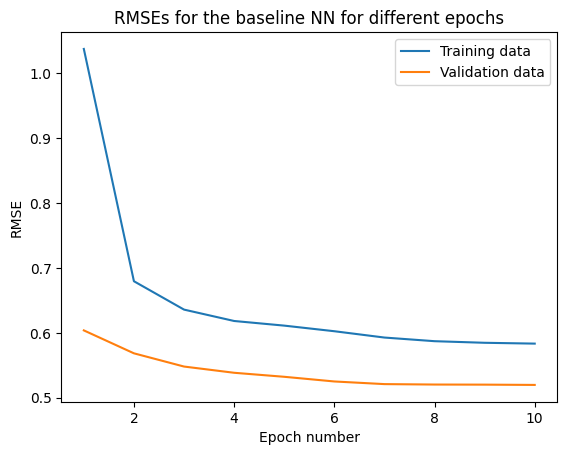

In [111]:
# Plot errors
fig, ax = plt.subplots(1,1)
epochs = range(1, num_epochs + 1)
ax.plot(epochs, errors["train"], label="Training data")
ax.plot(epochs, errors["validation"], label="Validation data")
ax.set_xlabel("Epoch number")
ax.set_ylabel("RMSE")
ax.set_title("RMSEs for the baseline NN for different epochs")
ax.legend()

As we can see, the model stops getting meaningfully better after around the fourth epoch. The linear regression had the validation RMSE 0.528. This lowest validation RMSE for this NN model was 0.519. Thus, the NN is slightly better than the linear regression. It is still worse than random forest which got 0.490455.

One interesting observation is that the validation RMSE is always lower than the training one.

Now, let's try a more complicated network.

## MLP

We'll first try with a two layer MLP. After each fully connected layer, we'll add a dropout layer to prevent overfitting.

In [112]:
class TwoLayerNN(torch.nn.Module):
  def __init__(self, input_size, hidden_sizes, output_size, dropout_prob):
    super().__init__()

    self.flatten = torch.nn.Flatten()
    self.stack = torch.nn.Sequential(
        torch.nn.Linear(input_size, hidden_sizes[0]),
        torch.nn.ReLU(),
        torch.nn.Dropout(dropout_prob),
        torch.nn.Linear(hidden_sizes[0], hidden_sizes[1]),
        torch.nn.ReLU(),
        torch.nn.Dropout(dropout_prob),
        torch.nn.Linear(hidden_sizes[1], output_size)
    )

  def forward(self, x):
    x = self.flatten(x)
    return self.stack(x)

nr_inputs = len(nn_df.columns) - 1 # nr of features
hidden_layer_sizes = (16, 8)
nr_outputs = 1
num_epochs = 20
dropout_p = 0.05
two_layer_nn = TwoLayerNN(nr_inputs, hidden_layer_sizes, nr_outputs, dropout_p)

# Seed randomness
torch.manual_seed(rs)

# train the model
errors = train_nn(two_layer_nn, train_loader, validation_loader, num_epochs)

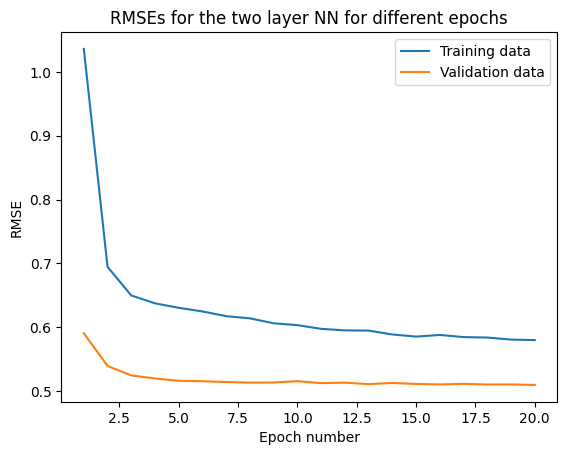

In [113]:
# Plot errors
fig, ax = plt.subplots(1,1)
epochs = range(1, num_epochs + 1)
ax.plot(epochs, errors["train"], label="Training data")
ax.plot(epochs, errors["validation"], label="Validation data")
ax.set_xlabel("Epoch number")
ax.set_ylabel("RMSE")
ax.set_title("RMSEs for the two layer NN for different epochs")
ax.legend()

In [114]:
print("Validation error:")
np.array(errors["validation"])[10:]

Validation error:


array([0.5126476 , 0.51338075, 0.51106203, 0.51287442, 0.51139145,
       0.51060327, 0.51147959, 0.51046447, 0.5105117 , 0.50982592])

At the end, we can see that the validation error doesn't change much while the training error steadily decreases. So we're going towards overfitting. Let's try other dropout errors.

The final RMSE this model got, 0.506, is only slightly better than the baseline model. The training error at the end also looks similar to the training error at the end of the baseline model. This suggests that the extra neurons and extra hidden layer aren't making performance much better. Let's try a wider one layer network.

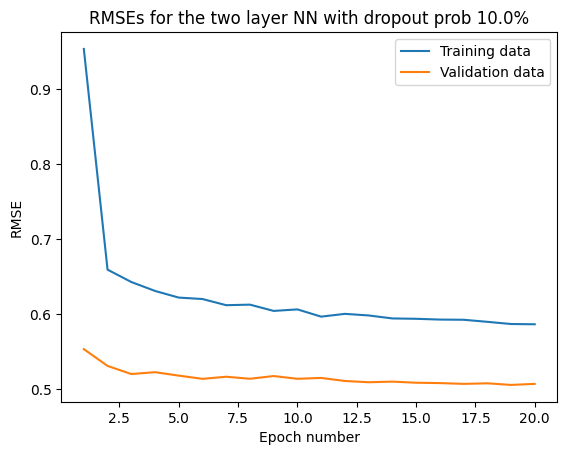

[0.50788863 0.50683944 0.50759746 0.50544541 0.50683973]
---


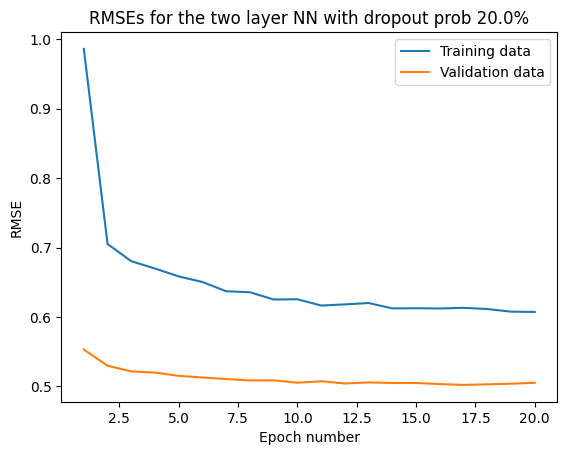

[0.5034108  0.5022153  0.50304064 0.50394213 0.50530167]
---


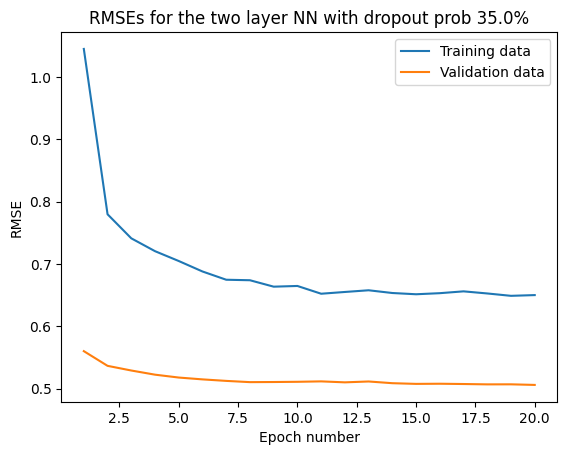

[0.50801728 0.50756235 0.50699992 0.50706779 0.50611496]
---


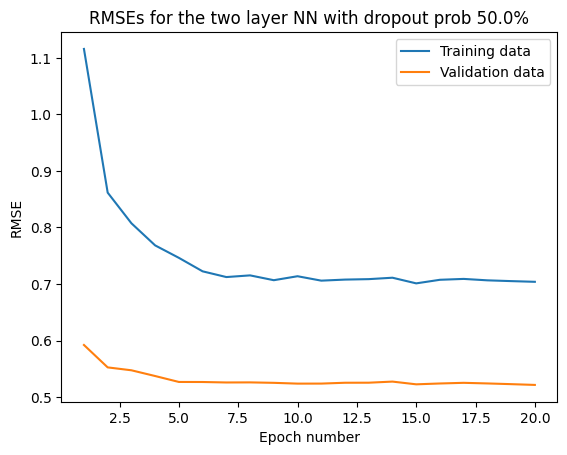

[0.5240103  0.52516489 0.52407786 0.5228177  0.52145709]
---


In [115]:
dropout_probs = [0.1, 0.2, 0.35, 0.5]
for p in dropout_probs:
  tl_nn = TwoLayerNN(nr_inputs, hidden_layer_sizes, nr_outputs, p)
  torch.manual_seed(rs)
  errors = train_nn(tl_nn, train_loader, validation_loader, num_epochs)

  fig, ax = plt.subplots(1,1)
  epochs = range(1, num_epochs + 1)
  ax.plot(epochs, errors["train"], label="Training data")
  ax.plot(epochs, errors["validation"], label="Validation data")
  ax.set_xlabel("Epoch number")
  ax.set_ylabel("RMSE")
  ax.set_title(f"RMSEs for the two layer NN with dropout prob {p*100}%")
  ax.legend()
  plt.show()
  print(np.array(errors["validation"])[15:])
  print("---")

It seems like 20% dropout gives the lowest RMSE with 0.502, although it isn't much better. On the other hand, 0.502 is better than linear regression's result of 0.528.

## Wider one layer NN

In [116]:
wider_nn =  BaseNN(nr_inputs, 16, nr_outputs)

# train the model
errors = train_nn(wider_nn, train_loader, validation_loader, num_epochs)

[0.50719676 0.50680983 0.50657955 0.50655114 0.50640922]


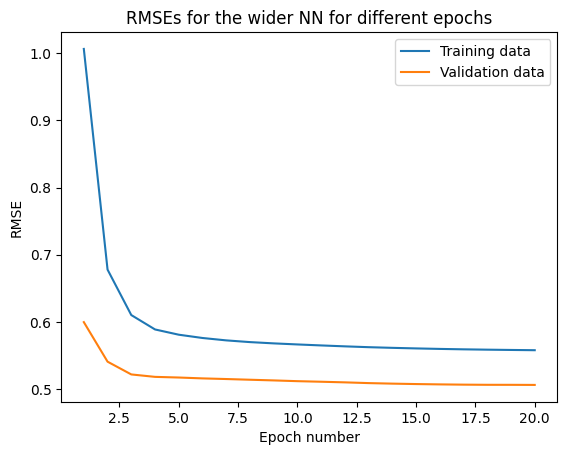

In [117]:
# Plot errors
fig, ax = plt.subplots(1,1)
epochs = range(1, num_epochs + 1)
ax.plot(epochs, errors["train"], label="Training data")
ax.plot(epochs, errors["validation"], label="Validation data")
ax.set_xlabel("Epoch number")
ax.set_ylabel("RMSE")
ax.set_title("RMSEs for the wider NN for different epochs")
ax.legend()
print(np.array(errors["validation"])[15:])

From all the models above, we can see that the error doesn't get much better. One possibility for this is that the 8 features don't contain enough information to predict the target more accurately.

Another possibility is that my lack of experience with NNs hinders me from creating a suitable NN for the dataset.

## Trying the full dataset

In [118]:
features_normalize = list(new_full_df.columns)
for x in ["Global_active_power", "hour", "day_of_week", "month"]:
  features_normalize.remove(x)

nn_df2 = new_full_df.copy()
nn_df2["hour_sin"] = np.sin( 2 * np.pi * nn_df2["hour"] / 24 )
nn_df2["hour_cos"] = np.cos( 2 * np.pi * nn_df2["hour"] / 24 )
nn_df2["day_of_week_sin"] = np.sin( 2 * np.pi * nn_df2["day_of_week"] / 7 )
nn_df2["day_of_week_cos"] = np.cos( 2 * np.pi * nn_df2["day_of_week"] / 7 )
nn_df2["month_sin"] = np.sin( 2 * np.pi * nn_df2["month"] / 12 )
nn_df2["month_cos"] = np.cos( 2 * np.pi * nn_df2["month"] / 12 )
nn_df2 = nn_df2.drop(["hour", "day_of_week", "month"], axis=1)

# Divide the dataset
nn_train_set2 =        nn_df2.iloc[:valid_cut_i]
nn_validation_set2 = nn_df2.iloc[valid_cut_i : test_cut_i]
nn_test_set2 =       nn_df2.iloc[test_cut_i:]

nn_train_set2 = nn_train_set2.drop(nn_train_set2.index[:24*7])
nn_full_train_set2 = pd.concat([nn_train_set2, nn_validation_set2])

# Normalize data
nn_train_set2 = normalize_data(nn_train_set2, fit=True, features=features_normalize)
nn_validation_set2 = normalize_data(nn_validation_set2, features=features_normalize)

nn_full_train_set2 = normalize_data(nn_full_train_set2, fit=True, features=features_normalize)
nn_test_set2 = normalize_data(nn_test_set2, features=features_normalize)

# Creating loaders
train_loader2      = create_loader(nn_train_set2)
full_train_loader2 = create_loader(nn_full_train_set2)
validation_loader2 = create_loader(nn_validation_set2)
test_loader2       = create_loader(nn_test_set2)

In [119]:
nr_inputs = len(nn_train_set2.columns) - 1 # nr of features
hidden_layer_sizes = (32, 16)
nr_outputs = 1
num_epochs = 30
dropout_p = 0.2

new_two_layer_nn = TwoLayerNN(nr_inputs, hidden_layer_sizes, nr_outputs, dropout_p)

# train the model
torch.manual_seed(rs)
errors = train_nn(two_layer_nn, train_loader, validation_loader, num_epochs)

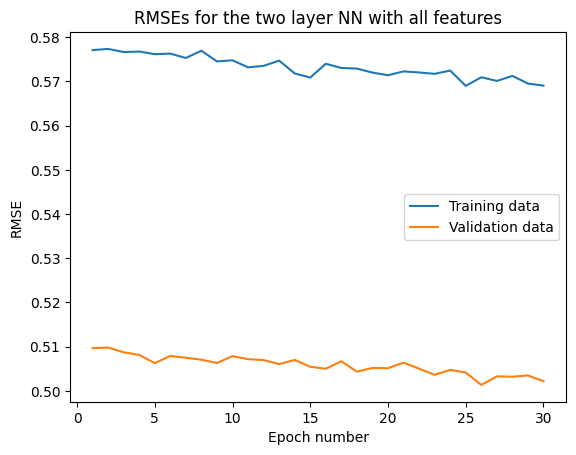

In [120]:
fig, ax = plt.subplots(1,1)
epochs = range(1, num_epochs + 1)
ax.plot(epochs, errors["train"], label="Training data")
ax.plot(epochs, errors["validation"], label="Validation data")
ax.set_xlabel("Epoch number")
ax.set_ylabel("RMSE")
ax.set_title("RMSEs for the two layer NN with all features")
ax.legend()

In [121]:
np.array(errors["validation"])

array([0.50965153, 0.50979247, 0.50872544, 0.5081311 , 0.50627673,
       0.50789491, 0.50749308, 0.50705304, 0.50629848, 0.50785621,
       0.50716397, 0.50696248, 0.50604931, 0.50700121, 0.50544981,
       0.50500462, 0.50669344, 0.5043439 , 0.5051788 , 0.50512677,
       0.5063815 , 0.50501988, 0.50362733, 0.50475657, 0.50414971,
       0.50134308, 0.50328148, 0.50319749, 0.50348015, 0.50220466])

As we can see, the validation doesn't get lower than 0.500 and keeps fluctuating. It's not much lower than when we used the reduced dataset either. The difference we saw with the HGB when using all features and only some features were greater than what we see here. So it seems like the HGB is better at extracting the additional information than our small NNs.

Still, by testing different NNs, we went from RMSE 0.519 with the single hidden layer to 0.500. Additional work with NNs can be made to find a network that has higher performance, perhaps using more advanced network models.

# Final error analysis


We'll finally investigate where our final model made mistakes. As a reminder, it's the following model:

In [122]:
best_hgb_pipeline

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('histgradientboostingregressor',
                 HistGradientBoostingRegressor(l2_regularization=np.float64(0.004070831640873338),
                                               learning_rate=np.float64(0.030816017044468066),
                                               max_iter=147, max_leaf_nodes=37,
                                               min_samples_leaf=71,
                                               random_state=42))])

In [123]:
n_errors_in_worst = 20

y_test = impr_test_set["Global_active_power"]

final_error_results = pd.DataFrame({
    "Actual": y_test,
    "Prediction": final_predictions
})

final_error_results["Error"] = final_error_results["Actual"] - final_error_results["Prediction"]
final_error_results["Absolute error"] = abs(final_error_results["Error"])
final_error_results["Squared error"] = final_error_results["Error"]**2
final_worst_errors = final_error_results.sort_values("Absolute error", ascending=False).head(n_errors_in_worst)
final_worst_performing_data = impr_test_set.loc[ final_worst_errors.index ]

In [124]:
n_errors = 10

d_test = final_worst_errors.head(n_errors)["Absolute error"].copy()
d_test = d_test.rename("Test set")
d_test.index = range(1, d_test.shape[0] + 1)

d_val = new_worst_errors.head(n_errors)["Absolute error"].copy()
d_val = d_val.rename("Validation set ")
d_val.index = range(1, d_val.shape[0] + 1)

print(f"Top {n_errors} worst absolute errors")
pd.concat([d_test, d_val], axis=1)

Top 10 worst absolute errors


,Test set,Validation set
1,3.560172,3.240069
2,2.737137,2.897955
3,2.666595,2.478050
4,2.294516,2.411908
5,2.268301,2.378757
6,2.218438,2.375073
7,2.206034,2.242380
8,2.193255,2.149075
9,2.091648,2.048940
10,1.968584,1.993675


From the table above, we can see that the worst absolute errors when evaluating our model on the test set is not that different from the when we evaluated on the validation set. This is nice, as it indicates that the model generalizes okay.

Let's take a look at how the worst errors are distributed in terms of hour and day.

Text(0.5, 1.0, 'The hour distribution of the worst errors from the final model')

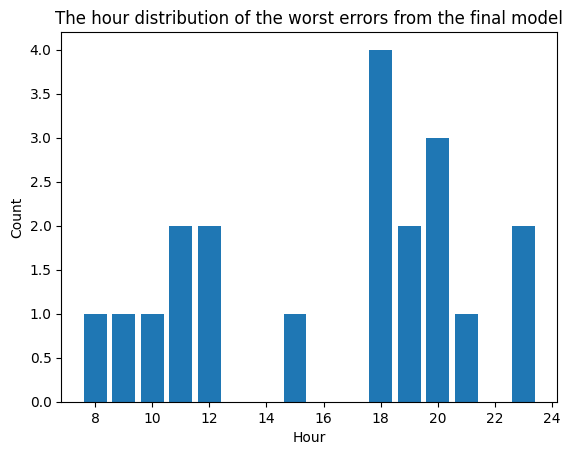

In [125]:
worst_hours = final_worst_performing_data["hour"].value_counts()

fig, ax = plt.subplots(1,1)
ax.bar(worst_hours.index, worst_hours.values)
ax.set_xlabel("Hour")
ax.set_ylabel("Count")
ax.set_title("The hour distribution of the worst errors from the final model")

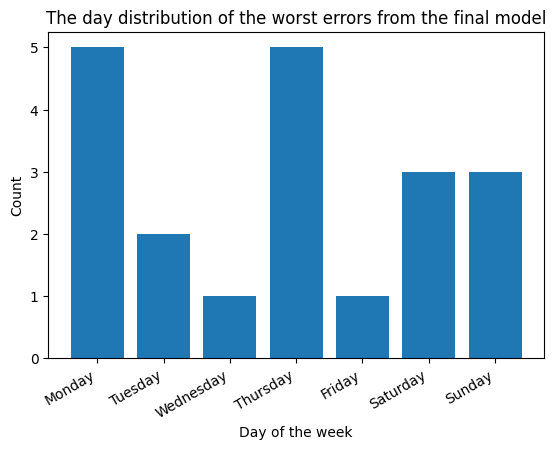

In [126]:
worst_days = final_worst_performing_data["day_of_week"].value_counts(sort = False)
worst_days = worst_days.sort_index()
worst_days.index = weekdays

fig, ax = plt.subplots(1,1)
ax.bar(worst_days.index, worst_days.values)
ax.set_xlabel("Day of the week")
ax.set_ylabel("Count")
ax.set_title("The day distribution of the worst errors from the final model")
fig.autofmt_xdate()

From the first plot, we can see that most of the worst errors are in the evening. This is also something we saw in our previous error analysis. A possible solution to reduce these errors could be to give more weight to the hour of the day.

As for the second plot, it is kind of fairly distributed. The most important point is that we cannot see a big difference between the weekdays and weekend as before. Rather, we seem to have a bigger difference within the weekdays. As we can see, Monday and Thursday seem to perform worse than the other days.

# Saving the final model

In [128]:
joblib.dump(best_hgb_pipeline, "electricity_consumption_hgb_model.pkl")

['electricity_consumption_hgb_model.pkl']